In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os

print("Libraries imported successfully!")

Libraries imported successfully!


In [ ]:
from google.colab import files

uploaded = files.upload()

Saving archive.zip to archive.zip


In [ ]:
import zipfile

with zipfile.ZipFile("archive.zip", "r") as zip_ref:
    zip_ref.extractall("/content/olist_data")

print("Dataset extracted successfully!")

Dataset extracted successfully!


In [ ]:
import os
import pandas as pd

data_path = "/content/olist_data"

files = {
    "customers": "olist_customers_dataset.csv",
    "geolocation": "olist_geolocation_dataset.csv",
    "order_items": "olist_order_items_dataset.csv",
    "payments": "olist_order_payments_dataset.csv",
    "reviews": "olist_order_reviews_dataset.csv",
    "orders": "olist_orders_dataset.csv",
    "products": "olist_products_dataset.csv",
    "sellers": "olist_sellers_dataset.csv",
    "category_translation": "product_category_name_translation.csv"
}

datasets = {}

for name, filename in files.items():
    filepath = os.path.join(data_path, filename)
    datasets[name] = pd.read_csv(filepath)
    print(f"{name}: Loaded successfully")

print("\nAll datasets loaded successfully!")

customers: Loaded successfully
geolocation: Loaded successfully
order_items: Loaded successfully
payments: Loaded successfully
reviews: Loaded successfully
orders: Loaded successfully
products: Loaded successfully
sellers: Loaded successfully
category_translation: Loaded successfully

All datasets loaded successfully!


In [ ]:
inventory = []

for name, df in datasets.items():
    inventory.append({
        "Dataset": name,
        "Rows": df.shape[0],
        "Columns": df.shape[1],
        "Missing Cells": df.isnull().sum().sum(),
        "Duplicate Rows": df.duplicated().sum(),
        "Memory (MB)": round(df.memory_usage(deep=True).sum() / (1024**2), 2)
    })

inventory_df = pd.DataFrame(inventory)

inventory_df

,Dataset,Rows,Columns,Missing Cells,Duplicate Rows,Memory (MB)
0,customers,99441,5,0,0,26.59
1,geolocation,1000163,5,0,261831,130.26
2,order_items,112650,7,0,0,35.99
3,payments,103886,5,0,0,16.23
4,reviews,99224,7,145903,0,39.12
5,orders,99441,8,4908,0,52.94
6,products,32951,9,2448,0,6.30
7,sellers,3095,4,0,0,0.59
8,category_translation,71,2,0,0,0.01


In [ ]:
orders = datasets["orders"]

print("Dataset Shape:", orders.shape)

print("\nColumn Names:")
print(orders.columns.tolist())

print("\nData Types:")
print(orders.dtypes)

print("\nFirst 5 Records:")
display(orders.head())

Dataset Shape: (99441, 8)

Column Names:
['order_id', 'customer_id', 'order_status', 'order_purchase_timestamp', 'order_approved_at', 'order_delivered_carrier_date', 'order_delivered_customer_date', 'order_estimated_delivery_date']

Data Types:
order_id                         object
customer_id                      object
order_status                     object
order_purchase_timestamp         object
order_approved_at                object
order_delivered_carrier_date     object
order_delivered_customer_date    object
order_estimated_delivery_date    object
dtype: object

First 5 Records:


,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18 00:00:00
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13 00:00:00
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04 00:00:00
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15 00:00:00
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26 00:00:00


In [ ]:
print("========== DATASET INVENTORY ==========")
display(inventory_df)

print("\n========== ORDERS DATASET ==========")
print("Shape:", orders.shape)

print("\nColumns and Data Types:")
display(pd.DataFrame({
    "Column": orders.columns,
    "Data Type": orders.dtypes.astype(str).values,
    "Missing Values": orders.isnull().sum().values
}))

print("\n========== SAMPLE RECORDS ==========")
display(orders.head(10))

========== DATASET INVENTORY ==========


,Dataset,Rows,Columns,Missing Cells,Duplicate Rows,Memory (MB)
0,customers,99441,5,0,0,26.59
1,geolocation,1000163,5,0,261831,130.26
2,order_items,112650,7,0,0,35.99
3,payments,103886,5,0,0,16.23
4,reviews,99224,7,145903,0,39.12
5,orders,99441,8,4908,0,52.94
6,products,32951,9,2448,0,6.30
7,sellers,3095,4,0,0,0.59
8,category_translation,71,2,0,0,0.01



========== ORDERS DATASET ==========
Shape: (99441, 8)

Columns and Data Types:


,Column,Data Type,Missing Values
0,order_id,object,0
1,customer_id,object,0
2,order_status,object,0
3,order_purchase_timestamp,object,0
4,order_approved_at,object,160
5,order_delivered_carrier_date,object,1783
6,order_delivered_customer_date,object,2965
7,order_estimated_delivery_date,object,0



========== SAMPLE RECORDS ==========


,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18 00:00:00
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13 00:00:00
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04 00:00:00
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15 00:00:00
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26 00:00:00
5,a4591c265e18cb1dcee52889e2d8acc3,503740e9ca751ccdda7ba28e9ab8f608,delivered,2017-07-09 21:57:05,2017-07-09 22:10:13,2017-07-11 14:58:04,2017-07-26 10:57:55,2017-08-01 00:00:00
6,136cce7faa42fdb2cefd53fdc79a6098,ed0271e0b7da060a393796590e7b737a,invoiced,2017-04-11 12:22:08,2017-04-13 13:25:17,NaN,NaN,2017-05-09 00:00:00
7,6514b8ad8028c9f2cc2374ded245783f,9bdf08b4b3b52b5526ff42d37d47f222,delivered,2017-05-16 13:10:30,2017-05-16 13:22:11,2017-05-22 10:07:46,2017-05-26 12:55:51,2017-06-07 00:00:00
8,76c6e866289321a7c93b82b54852dc33,f54a9f0e6b351c431402b8461ea51999,delivered,2017-01-23 18:29:09,2017-01-25 02:50:47,2017-01-26 14:16:31,2017-02-02 14:08:10,2017-03-06 00:00:00
9,e69bfb5eb88e0ed6a785585b27e16dbf,31ad1d1b63eb9962463f764d4e6e0c9d,delivered,2017-07-29 11:55:02,2017-07-29 12:05:32,2017-08-10 19:45:24,2017-08-16 17:14:30,2017-08-23 00:00:00


In [ ]:
# Missing value investigation

for name, df in datasets.items():

    print("\n" + "="*60)
    print(f"DATASET: {name.upper()}")
    print("="*60)

    missing = df.isnull().sum()

    missing_report = pd.DataFrame({
        "Missing_Count": missing,
        "Missing_Percentage": (missing / len(df) * 100).round(2)
    })

    missing_report = missing_report[
        missing_report["Missing_Count"] > 0
    ].sort_values("Missing_Count", ascending=False)

    if missing_report.empty:
        print("No missing values found.")
    else:
        display(missing_report)


DATASET: CUSTOMERS
No missing values found.

DATASET: GEOLOCATION
No missing values found.

DATASET: ORDER_ITEMS
No missing values found.

DATASET: PAYMENTS
No missing values found.

DATASET: REVIEWS


,Missing_Count,Missing_Percentage
review_comment_title,87656,88.34
review_comment_message,58247,58.70



DATASET: ORDERS


,Missing_Count,Missing_Percentage
order_delivered_customer_date,2965,2.98
order_delivered_carrier_date,1783,1.79
order_approved_at,160,0.16



DATASET: PRODUCTS


,Missing_Count,Missing_Percentage
product_category_name,610,1.85
product_name_lenght,610,1.85
product_description_lenght,610,1.85
product_photos_qty,610,1.85
product_weight_g,2,0.01
product_length_cm,2,0.01
product_height_cm,2,0.01
product_width_cm,2,0.01



DATASET: SELLERS
No missing values found.

DATASET: CATEGORY_TRANSLATION
No missing values found.


In [ ]:
# Order status distribution

status_report = (
    orders["order_status"]
    .value_counts()
    .reset_index()
)

status_report.columns = ["Order_Status", "Order_Count"]

status_report["Percentage"] = (
    status_report["Order_Count"] /
    len(orders) * 100
).round(2)

display(status_report)

,Order_Status,Order_Count,Percentage
0,delivered,96478,97.02
1,shipped,1107,1.11
2,canceled,625,0.63
3,unavailable,609,0.61
4,invoiced,314,0.32
5,processing,301,0.30
6,created,5,0.01
7,approved,2,0.00


In [ ]:
geo = datasets["geolocation"]

print("Total geolocation records:", len(geo))

print(
    "Exact duplicate rows:",
    geo.duplicated().sum()
)

print(
    "Duplicate zip code prefixes:",
    geo["geolocation_zip_code_prefix"].duplicated().sum()
)

print(
    "Unique zip code prefixes:",
    geo["geolocation_zip_code_prefix"].nunique()
)

print(
    "Unique latitude/longitude combinations:",
    geo[[
        "geolocation_lat",
        "geolocation_lng"
    ]].drop_duplicates().shape[0]
)

Total geolocation records: 1000163
Exact duplicate rows: 261831
Duplicate zip code prefixes: 981148
Unique zip code prefixes: 19015
Unique latitude/longitude combinations: 718463


In [ ]:
print("Total order records:", len(orders))

print(
    "Unique order IDs:",
    orders["order_id"].nunique()
)

print(
    "Duplicate order IDs:",
    orders["order_id"].duplicated().sum()
)

print(
    "Unique customer IDs:",
    orders["customer_id"].nunique()
)

Total order records: 99441
Unique order IDs: 99441
Duplicate order IDs: 0
Unique customer IDs: 99441


In [ ]:
for name, df in datasets.items():
    print(f"\n{name.upper()}")
    print("Rows:", len(df))
    print("Missing cells:", df.isnull().sum().sum())
    print("Exact duplicate rows:", df.duplicated().sum())


CUSTOMERS
Rows: 99441
Missing cells: 0
Exact duplicate rows: 0

GEOLOCATION
Rows: 1000163
Missing cells: 0
Exact duplicate rows: 261831

ORDER_ITEMS
Rows: 112650
Missing cells: 0
Exact duplicate rows: 0

PAYMENTS
Rows: 103886
Missing cells: 0
Exact duplicate rows: 0

REVIEWS
Rows: 99224
Missing cells: 145903
Exact duplicate rows: 0

ORDERS
Rows: 99441
Missing cells: 4908
Exact duplicate rows: 0

PRODUCTS
Rows: 32951
Missing cells: 2448
Exact duplicate rows: 0

SELLERS
Rows: 3095
Missing cells: 0
Exact duplicate rows: 0

CATEGORY_TRANSLATION
Rows: 71
Missing cells: 0
Exact duplicate rows: 0


In [ ]:
reviews = datasets["reviews"]

review_missing = pd.DataFrame({
    "Missing_Count": reviews.isnull().sum(),
    "Missing_Percentage": (
        reviews.isnull().mean() * 100
    ).round(2)
})

display(review_missing)

,Missing_Count,Missing_Percentage
review_id,0,0.00
order_id,0,0.00
review_score,0,0.00
review_comment_title,87656,88.34
review_comment_message,58247,58.70
review_creation_date,0,0.00
review_answer_timestamp,0,0.00


In [ ]:
orders_missing = pd.DataFrame({
    "Missing_Count": orders.isnull().sum(),
    "Missing_Percentage": (
        orders.isnull().mean() * 100
    ).round(2)
})

display(orders_missing)

print("\nMissing values by order status:")

missing_by_status = orders.groupby(
    "order_status"
)[
    [
        "order_approved_at",
        "order_delivered_carrier_date",
        "order_delivered_customer_date"
    ]
].apply(lambda x: x.isnull().sum())

display(missing_by_status)

,Missing_Count,Missing_Percentage
order_id,0,0.00
customer_id,0,0.00
order_status,0,0.00
order_purchase_timestamp,0,0.00
order_approved_at,160,0.16
order_delivered_carrier_date,1783,1.79
order_delivered_customer_date,2965,2.98
order_estimated_delivery_date,0,0.00



Missing values by order status:


,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date
order_status,,,
approved,0,2,2
canceled,141,550,619
created,5,5,5
delivered,14,2,8
invoiced,0,314,314
processing,0,301,301
shipped,0,0,1107
unavailable,0,609,609


In [ ]:
products = datasets["products"]

products_missing = pd.DataFrame({
    "Missing_Count": products.isnull().sum(),
    "Missing_Percentage": (
        products.isnull().mean() * 100
    ).round(2)
})

display(products_missing)

,Missing_Count,Missing_Percentage
product_id,0,0.00
product_category_name,610,1.85
product_name_lenght,610,1.85
product_description_lenght,610,1.85
product_photos_qty,610,1.85
product_weight_g,2,0.01
product_length_cm,2,0.01
product_height_cm,2,0.01
product_width_cm,2,0.01


In [ ]:
geo = datasets["geolocation"]

print("Original records:", len(geo))
print("Exact duplicate records:", geo.duplicated().sum())

print("\nSample duplicate records:")

display(
    geo[geo.duplicated(keep=False)].head(10)
)

Original records: 1000163
Exact duplicate records: 261831

Sample duplicate records:


,geolocation_zip_code_prefix,geolocation_lat,geolocation_lng,geolocation_city,geolocation_state
0,1037,-23.545621,-46.639292,sao paulo,SP
1,1046,-23.546081,-46.644820,sao paulo,SP
2,1046,-23.546129,-46.642951,sao paulo,SP
6,1047,-23.546273,-46.641225,sao paulo,SP
7,1013,-23.546923,-46.634264,sao paulo,SP
8,1029,-23.543769,-46.634278,sao paulo,SP
9,1011,-23.547640,-46.636032,sao paulo,SP
10,1013,-23.547325,-46.634184,sao paulo,SP
13,1012,-23.548946,-46.634671,sao paulo,SP
15,1046,-23.546081,-46.644820,sao paulo,SP


In [ ]:
products = datasets["products"]

product_missing_rows = products[
    products["product_category_name"].isnull()
]

print("Products with missing categories:",
      len(product_missing_rows))

print("\nMissing values in these records:")
display(product_missing_rows.isnull().sum())

print("\nSample affected products:")
display(product_missing_rows.head(10))

Products with missing categories: 610

Missing values in these records:


,0
product_id,0
product_category_name,610
product_name_lenght,610
product_description_lenght,610
product_photos_qty,610
product_weight_g,1
product_length_cm,1
product_height_cm,1
product_width_cm,1



Sample affected products:


,product_id,product_category_name,product_name_lenght,product_description_lenght,product_photos_qty,product_weight_g,product_length_cm,product_height_cm,product_width_cm
105,a41e356c76fab66334f36de622ecbd3a,NaN,NaN,NaN,NaN,650.0,17.0,14.0,12.0
128,d8dee61c2034d6d075997acef1870e9b,NaN,NaN,NaN,NaN,300.0,16.0,7.0,20.0
145,56139431d72cd51f19eb9f7dae4d1617,NaN,NaN,NaN,NaN,200.0,20.0,20.0,20.0
154,46b48281eb6d663ced748f324108c733,NaN,NaN,NaN,NaN,18500.0,41.0,30.0,41.0
197,5fb61f482620cb672f5e586bb132eae9,NaN,NaN,NaN,NaN,300.0,35.0,7.0,12.0
244,e10758160da97891c2fdcbc35f0f031d,NaN,NaN,NaN,NaN,2200.0,16.0,2.0,11.0
294,39e3b9b12cd0bf8ee681bbc1c130feb5,NaN,NaN,NaN,NaN,300.0,16.0,7.0,11.0
299,794de06c32a626a5692ff50e4985d36f,NaN,NaN,NaN,NaN,300.0,18.0,8.0,14.0
347,7af3e2da474486a3519b0cba9dea8ad9,NaN,NaN,NaN,NaN,200.0,22.0,14.0,14.0
428,629beb8e7317703dcc5f35b5463fd20e,NaN,NaN,NaN,NaN,1400.0,25.0,25.0,25.0


In [ ]:
delivered_orders = orders[
    orders["order_status"] == "delivered"
]

print("Total delivered orders:", len(delivered_orders))

print("\nMissing timestamps in delivered orders:")

display(
    delivered_orders.isnull().sum()
)

print("\nSample affected records:")

display(
    delivered_orders[
        delivered_orders[
            [
                "order_approved_at",
                "order_delivered_carrier_date",
                "order_delivered_customer_date"
            ]
        ].isnull().any(axis=1)
    ].head(10)
)

Total delivered orders: 96478

Missing timestamps in delivered orders:


,0
order_id,0
customer_id,0
order_status,0
order_purchase_timestamp,0
order_approved_at,14
order_delivered_carrier_date,2
order_delivered_customer_date,8
order_estimated_delivery_date,0



Sample affected records:


,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
3002,2d1e2d5bf4dc7227b3bfebb81328c15f,ec05a6d8558c6455f0cbbd8a420ad34f,delivered,2017-11-28 17:44:07,2017-11-28 17:56:40,2017-11-30 18:12:23,NaN,2017-12-18 00:00:00
5323,e04abd8149ef81b95221e88f6ed9ab6a,2127dc6603ac33544953ef05ec155771,delivered,2017-02-18 14:40:00,NaN,2017-02-23 12:04:47,2017-03-01 13:25:33,2017-03-17 00:00:00
16567,8a9adc69528e1001fc68dd0aaebbb54a,4c1ccc74e00993733742a3c786dc3c1f,delivered,2017-02-18 12:45:31,NaN,2017-02-23 09:01:52,2017-03-02 10:05:06,2017-03-21 00:00:00
19031,7013bcfc1c97fe719a7b5e05e61c12db,2941af76d38100e0f8740a374f1a5dc3,delivered,2017-02-18 13:29:47,NaN,2017-02-22 16:25:25,2017-03-01 08:07:38,2017-03-17 00:00:00
20618,f5dd62b788049ad9fc0526e3ad11a097,5e89028e024b381dc84a13a3570decb4,delivered,2018-06-20 06:58:43,2018-06-20 07:19:05,2018-06-25 08:05:00,NaN,2018-07-16 00:00:00
22663,5cf925b116421afa85ee25e99b4c34fb,29c35fc91fc13fb5073c8f30505d860d,delivered,2017-02-18 16:48:35,NaN,2017-02-22 11:23:10,2017-03-09 07:28:47,2017-03-31 00:00:00
23156,12a95a3c06dbaec84bcfb0e2da5d228a,1e101e0daffaddce8159d25a8e53f2b2,delivered,2017-02-17 13:05:55,NaN,2017-02-22 11:23:11,2017-03-02 11:09:19,2017-03-20 00:00:00
26800,c1d4211b3dae76144deccd6c74144a88,684cb238dc5b5d6366244e0e0776b450,delivered,2017-01-19 12:48:08,NaN,2017-01-25 14:56:50,2017-01-30 18:16:01,2017-03-01 00:00:00
38290,d69e5d356402adc8cf17e08b5033acfb,68d081753ad4fe22fc4d410a9eb1ca01,delivered,2017-02-19 01:28:47,NaN,2017-02-23 03:11:48,2017-03-02 03:41:58,2017-03-27 00:00:00
39334,d77031d6a3c8a52f019764e68f211c69,0bf35cac6cc7327065da879e2d90fae8,delivered,2017-02-18 11:04:19,NaN,2017-02-23 07:23:36,2017-03-02 16:15:23,2017-03-22 00:00:00


In [ ]:
geo = datasets["geolocation"]

geo_clean_preview = geo.drop_duplicates()

print("Original geolocation records:", len(geo))

print("Records after removing exact duplicates:",
      len(geo_clean_preview))

print("Records removed:",
      len(geo) - len(geo_clean_preview))

print("Remaining exact duplicates:",
      geo_clean_preview.duplicated().sum())

Original geolocation records: 1000163
Records after removing exact duplicates: 738332
Records removed: 261831
Remaining exact duplicates: 0


In [ ]:
# Identify products with missing categories

missing_category_products = products[
    products["product_category_name"].isnull()
]["product_id"]

# Check whether they appear in order items

order_items = datasets["order_items"]

affected_items = order_items[
    order_items["product_id"].isin(
        missing_category_products
    )
]

print("Products with missing categories:",
      len(missing_category_products))

print("Matching order item records:",
      len(affected_items))

print("Unique affected products:",
      affected_items["product_id"].nunique())

print("Total affected sales value:",
      affected_items["price"].sum())

print("Total affected freight value:",
      affected_items["freight_value"].sum())

Products with missing categories: 610
Matching order item records: 1603
Unique affected products: 610
Total affected sales value: 179535.28
Total affected freight value: 28169.809999999998


In [ ]:
dimension_columns = [
    "product_weight_g",
    "product_length_cm",
    "product_height_cm",
    "product_width_cm"
]

display(
    products[
        products[dimension_columns].isnull().any(axis=1)
    ]
)

,product_id,product_category_name,product_name_lenght,product_description_lenght,product_photos_qty,product_weight_g,product_length_cm,product_height_cm,product_width_cm
8578,09ff539a621711667c43eba6a3bd8466,bebes,60.0,865.0,3.0,NaN,NaN,NaN,NaN
18851,5eb564652db742ff8f28759cd8d2652a,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [ ]:
# Create separate working copies of all datasets

cleaned_datasets = {
    name: df.copy(deep=True)
    for name, df in datasets.items()
}

print("Working copies created successfully!")

print("Original datasets:", len(datasets))
print("Working datasets:", len(cleaned_datasets))

Working copies created successfully!
Original datasets: 9
Working datasets: 9


In [ ]:
geo_clean = cleaned_datasets["geolocation"].copy()

original_geo_count = len(geo_clean)

geo_clean = geo_clean.drop_duplicates().copy()

cleaned_geo_count = len(geo_clean)

print("Original records:", original_geo_count)
print("Records after cleaning:", cleaned_geo_count)
print("Records removed:", original_geo_count - cleaned_geo_count)
print("Remaining duplicates:", geo_clean.duplicated().sum())

cleaned_datasets["geolocation"] = geo_clean

Original records: 1000163
Records after cleaning: 738332
Records removed: 261831
Remaining duplicates: 0


In [ ]:
products_clean = cleaned_datasets["products"].copy()

products_clean["product_category_name"] = (
    products_clean["product_category_name"]
    .fillna("Unknown")
)

print("Missing product categories:",
      products_clean["product_category_name"].isnull().sum())

print("\nUnknown product categories:",
      (products_clean["product_category_name"] == "Unknown").sum())

cleaned_datasets["products"] = products_clean

Missing product categories: 0

Unknown product categories: 610


In [ ]:
reviews_clean = cleaned_datasets["reviews"].copy()

reviews_clean["review_comment_title_clean"] = (
    reviews_clean["review_comment_title"]
    .fillna("No comment")
)

reviews_clean["review_comment_message_clean"] = (
    reviews_clean["review_comment_message"]
    .fillna("No comment")
)

print("Missing review scores:",
      reviews_clean["review_score"].isnull().sum())

print("Missing cleaned comment titles:",
      reviews_clean["review_comment_title_clean"].isnull().sum())

print("Missing cleaned comment messages:",
      reviews_clean["review_comment_message_clean"].isnull().sum())

cleaned_datasets["reviews"] = reviews_clean

Missing review scores: 0
Missing cleaned comment titles: 0
Missing cleaned comment messages: 0


In [ ]:
orders_clean = cleaned_datasets["orders"].copy()

date_columns = [
    "order_purchase_timestamp",
    "order_approved_at",
    "order_delivered_carrier_date",
    "order_delivered_customer_date",
    "order_estimated_delivery_date"
]

for column in date_columns:
    orders_clean[column] = pd.to_datetime(
        orders_clean[column],
        errors="coerce"
    )

print(orders_clean[date_columns].dtypes)

cleaned_datasets["orders"] = orders_clean

order_purchase_timestamp         datetime64[ns]
order_approved_at                datetime64[ns]
order_delivered_carrier_date     datetime64[ns]
order_delivered_customer_date    datetime64[ns]
order_estimated_delivery_date    datetime64[ns]
dtype: object


In [ ]:
print("========== CLEANING VERIFICATION ==========")

for name, df in cleaned_datasets.items():

    print(f"\n{name.upper()}")
    print("Rows:", len(df))
    print("Columns:", len(df.columns))
    print("Missing cells:", df.isnull().sum().sum())
    print("Duplicate rows:", df.duplicated().sum())

print("\nAll cleaning operations completed.")

========== CLEANING VERIFICATION ==========

CUSTOMERS
Rows: 99441
Columns: 5
Missing cells: 0
Duplicate rows: 0

GEOLOCATION
Rows: 738332
Columns: 5
Missing cells: 0
Duplicate rows: 0

ORDER_ITEMS
Rows: 112650
Columns: 7
Missing cells: 0
Duplicate rows: 0

PAYMENTS
Rows: 103886
Columns: 5
Missing cells: 0
Duplicate rows: 0

REVIEWS
Rows: 99224
Columns: 9
Missing cells: 145903
Duplicate rows: 0

ORDERS
Rows: 99441
Columns: 8
Missing cells: 4908
Duplicate rows: 0

PRODUCTS
Rows: 32951
Columns: 9
Missing cells: 1838
Duplicate rows: 0

SELLERS
Rows: 3095
Columns: 4
Missing cells: 0
Duplicate rows: 0

CATEGORY_TRANSLATION
Rows: 71
Columns: 2
Missing cells: 0
Duplicate rows: 0

All cleaning operations completed.


In [ ]:
# Check whether important ID columns contain duplicates

key_columns = {
    "customers": "customer_id",
    "orders": "order_id",
    "products": "product_id",
    "sellers": "seller_id",
    "category_translation": "product_category_name"
}

for table, column in key_columns.items():
    df = cleaned_datasets[table]

    print(f"\n{table.upper()}")
    print("Total records:", len(df))
    print("Unique values:", df[column].nunique())
    print("Duplicate values:", df[column].duplicated().sum())


CUSTOMERS
Total records: 99441
Unique values: 99441
Duplicate values: 0

ORDERS
Total records: 99441
Unique values: 99441
Duplicate values: 0

PRODUCTS
Total records: 32951
Unique values: 32951
Duplicate values: 0

SELLERS
Total records: 3095
Unique values: 3095
Duplicate values: 0

CATEGORY_TRANSLATION
Total records: 71
Unique values: 71
Duplicate values: 0


In [ ]:
# Check foreign-key relationships

checks = {
    "Orders -> Customers": (
        cleaned_datasets["orders"],
        "customer_id",
        cleaned_datasets["customers"],
        "customer_id"
    ),

    "Order Items -> Orders": (
        cleaned_datasets["order_items"],
        "order_id",
        cleaned_datasets["orders"],
        "order_id"
    ),

    "Order Items -> Products": (
        cleaned_datasets["order_items"],
        "product_id",
        cleaned_datasets["products"],
        "product_id"
    ),

    "Order Items -> Sellers": (
        cleaned_datasets["order_items"],
        "seller_id",
        cleaned_datasets["sellers"],
        "seller_id"
    ),

    "Payments -> Orders": (
        cleaned_datasets["payments"],
        "order_id",
        cleaned_datasets["orders"],
        "order_id"
    ),

    "Reviews -> Orders": (
        cleaned_datasets["reviews"],
        "order_id",
        cleaned_datasets["orders"],
        "order_id"
    )
}

for relationship, (child, child_col, parent, parent_col) in checks.items():

    unmatched = ~child[child_col].isin(parent[parent_col])

    print(f"\n{relationship}")
    print("Total records:", len(child))
    print("Unmatched records:", unmatched.sum())
    print("Matched records:", (~unmatched).sum())


Orders -> Customers
Total records: 99441
Unmatched records: 0
Matched records: 99441

Order Items -> Orders
Total records: 112650
Unmatched records: 0
Matched records: 112650

Order Items -> Products
Total records: 112650
Unmatched records: 0
Matched records: 112650

Order Items -> Sellers
Total records: 112650
Unmatched records: 0
Matched records: 112650

Payments -> Orders
Total records: 103886
Unmatched records: 0
Matched records: 103886

Reviews -> Orders
Total records: 99224
Unmatched records: 0
Matched records: 99224


In [ ]:
# Examine order-item and payment relationships

order_items = cleaned_datasets["order_items"]
payments = cleaned_datasets["payments"]
orders = cleaned_datasets["orders"]

print("========== ORDER STRUCTURE ==========")

print("Total orders:", orders["order_id"].nunique())
print("Total order-item records:", len(order_items))
print("Orders with multiple items:",
      (order_items.groupby("order_id").size() > 1).sum())

print("\n========== PAYMENT STRUCTURE ==========")

print("Total payment records:", len(payments))
print("Unique orders with payments:", payments["order_id"].nunique())
print("Orders with multiple payment records:",
      (payments.groupby("order_id").size() > 1).sum())

========== ORDER STRUCTURE ==========
Total orders: 99441
Total order-item records: 112650
Orders with multiple items: 9803

========== PAYMENT STRUCTURE ==========
Total payment records: 103886
Unique orders with payments: 99440
Orders with multiple payment records: 2961


In [ ]:
# Identify orders without payment records

orders_without_payment = orders[
    ~orders["order_id"].isin(payments["order_id"])
]

print("Orders without payment records:",
      len(orders_without_payment))

print("\nOrder details:")

print(
    orders_without_payment[
        [
            "order_id",
            "customer_id",
            "order_status",
            "order_purchase_timestamp"
        ]
    ]
)

Orders without payment records: 1

Order details:
                               order_id                       customer_id  \
30710  bfbd0f9bdef84302105ad712db648a6c  86dc2ffce2dfff336de2f386a786e574   

      order_status order_purchase_timestamp  
30710    delivered      2016-09-15 12:16:38  


In [ ]:
# Check orders without items and orders without reviews

orders_without_items = orders[
    ~orders["order_id"].isin(order_items["order_id"])
]

orders_without_reviews = orders[
    ~orders["order_id"].isin(
        cleaned_datasets["reviews"]["order_id"]
    )
]

print("========== ORDER COMPLETENESS ==========")

print("Total orders:", orders["order_id"].nunique())

print("Orders without items:",
      len(orders_without_items))

print("Orders without payments:",
      len(orders_without_payment))

print("Orders without reviews:",
      len(orders_without_reviews))

print("\n========== ORDER STATUS ==========")

print(
    orders_without_items["order_status"].value_counts()
)

print("\nOrders without reviews by status:")

print(
    orders_without_reviews["order_status"].value_counts()
)

========== ORDER COMPLETENESS ==========
Total orders: 99441
Orders without items: 775
Orders without payments: 1
Orders without reviews: 768

========== ORDER STATUS ==========
order_status
unavailable    603
canceled       164
created          5
invoiced         2
shipped          1
Name: count, dtype: int64

Orders without reviews by status:
order_status
delivered      646
shipped         75
canceled        20
unavailable     14
processing       6
invoiced         5
created          2
Name: count, dtype: int64


In [ ]:
# Create a data-quality summary

quality_summary = pd.DataFrame({
    "Issue": [
        "Duplicate geolocation records removed",
        "Products with unknown categories",
        "Orders without items",
        "Orders without payment records",
        "Orders without reviews",
        "Orders with missing delivery dates",
        "Products with missing physical measurements"
    ],

    "Affected_Records": [
        261831,
        610,
        len(orders_without_items),
        len(orders_without_payment),
        len(orders_without_reviews),
        orders["order_delivered_customer_date"].isnull().sum(),
        cleaned_datasets["products"][
            ["product_weight_g", "product_length_cm",
             "product_height_cm", "product_width_cm"]
        ].isnull().any(axis=1).sum()
    ]
})

print(quality_summary.to_string(index=False))

                                      Issue  Affected_Records
      Duplicate geolocation records removed            261831
           Products with unknown categories               610
                       Orders without items               775
             Orders without payment records                 1
                     Orders without reviews               768
         Orders with missing delivery dates              2965
Products with missing physical measurements                 2


In [ ]:
# Prepare sales analysis dataset

sales = cleaned_datasets["order_items"].copy()

# Attach purchase date and order status
sales = sales.merge(
    cleaned_datasets["orders"][
        ["order_id", "order_purchase_timestamp", "order_status"]
    ],
    on="order_id",
    how="left"
)

# Create purchase month
sales["purchase_month"] = (
    sales["order_purchase_timestamp"].dt.to_period("M")
)

# Calculate item-level sales value
sales["total_item_value"] = (
    sales["price"] + sales["freight_value"]
)

print("Sales dataset shape:", sales.shape)

print("\nFirst five records:")
display(sales.head())

print("\nMissing values:")
print(sales.isnull().sum())

Sales dataset shape: (112650, 11)

First five records:


,order_id,order_item_id,product_id,seller_id,shipping_limit_date,price,freight_value,order_purchase_timestamp,order_status,purchase_month,total_item_value
0,00010242fe8c5a6d1ba2dd792cb16214,1,4244733e06e7ecb4970a6e2683c13e61,48436dade18ac8b2bce089ec2a041202,2017-09-19 09:45:35,58.90,13.29,2017-09-13 08:59:02,delivered,2017-09,72.19
1,00018f77f2f0320c557190d7a144bdd3,1,e5f2d52b802189ee658865ca93d83a8f,dd7ddc04e1b6c2c614352b383efe2d36,2017-05-03 11:05:13,239.90,19.93,2017-04-26 10:53:06,delivered,2017-04,259.83
2,000229ec398224ef6ca0657da4fc703e,1,c777355d18b72b67abbeef9df44fd0fd,5b51032eddd242adc84c38acab88f23d,2018-01-18 14:48:30,199.00,17.87,2018-01-14 14:33:31,delivered,2018-01,216.87
3,00024acbcdf0a6daa1e931b038114c75,1,7634da152a4610f1595efa32f14722fc,9d7a1d34a5052409006425275ba1c2b4,2018-08-15 10:10:18,12.99,12.79,2018-08-08 10:00:35,delivered,2018-08,25.78
4,00042b26cf59d7ce69dfabb4e55b4fd9,1,ac6c3623068f30de03045865e4e10089,df560393f3a51e74553ab94004ba5c87,2017-02-13 13:57:51,199.90,18.14,2017-02-04 13:57:51,delivered,2017-02,218.04



Missing values:
order_id                    0
order_item_id               0
product_id                  0
seller_id                   0
shipping_limit_date         0
price                       0
freight_value               0
order_purchase_timestamp    0
order_status                0
purchase_month              0
total_item_value            0
dtype: int64


In [ ]:
# Calculate key sales performance metrics

total_orders = sales["order_id"].nunique()

total_items = len(sales)

total_merchandise_sales = sales["price"].sum()

total_freight = sales["freight_value"].sum()

total_sales_including_freight = (
    total_merchandise_sales + total_freight
)

average_order_value = (
    total_merchandise_sales / total_orders
)

average_item_price = sales["price"].mean()

average_freight_per_item = sales["freight_value"].mean()

# Display results

print("========== SALES PERFORMANCE ==========")

print(f"Total Orders: {total_orders:,}")

print(f"Total Items Sold: {total_items:,}")

print(f"Total Merchandise Sales: R${total_merchandise_sales:,.2f}")

print(f"Total Freight Value: R${total_freight:,.2f}")

print(
    f"Total Sales Including Freight: "
    f"R${total_sales_including_freight:,.2f}"
)

print(f"Average Order Value: R${average_order_value:,.2f}")

print(f"Average Item Price: R${average_item_price:,.2f}")

print(
    f"Average Freight per Item: "
    f"R${average_freight_per_item:,.2f}"
)

========== SALES PERFORMANCE ==========
Total Orders: 98,666
Total Items Sold: 112,650
Total Merchandise Sales: R$13,591,643.70
Total Freight Value: R$2,251,909.54
Total Sales Including Freight: R$15,843,553.24
Average Order Value: R$137.75
Average Item Price: R$120.65
Average Freight per Item: R$19.99


In [ ]:
# Monthly sales performance

monthly_sales = (
    sales.groupby("purchase_month")
    .agg(
        merchandise_sales=("price", "sum"),
        total_orders=("order_id", "nunique"),
        items_sold=("order_item_id", "count")
    )
    .reset_index()
)

# Calculate monthly average order value
monthly_sales["average_order_value"] = (
    monthly_sales["merchandise_sales"] /
    monthly_sales["total_orders"]
)

# Convert month to string for display
monthly_sales["purchase_month"] = (
    monthly_sales["purchase_month"].astype(str)
)

print("========== MONTHLY SALES PERFORMANCE ==========")

display(monthly_sales.round(2))

========== MONTHLY SALES PERFORMANCE ==========


,purchase_month,merchandise_sales,total_orders,items_sold,average_order_value
0,2016-09,267.36,3,6,89.12
1,2016-10,49507.66,308,363,160.74
2,2016-12,10.90,1,1,10.90
3,2017-01,120312.87,789,955,152.49
4,2017-02,247303.02,1733,1951,142.70
5,2017-03,374344.30,2641,3000,141.74
6,2017-04,359927.23,2391,2684,150.53
7,2017-05,506071.14,3660,4136,138.27
8,2017-06,433038.60,3217,3583,134.61
9,2017-07,498031.48,3969,4519,125.48


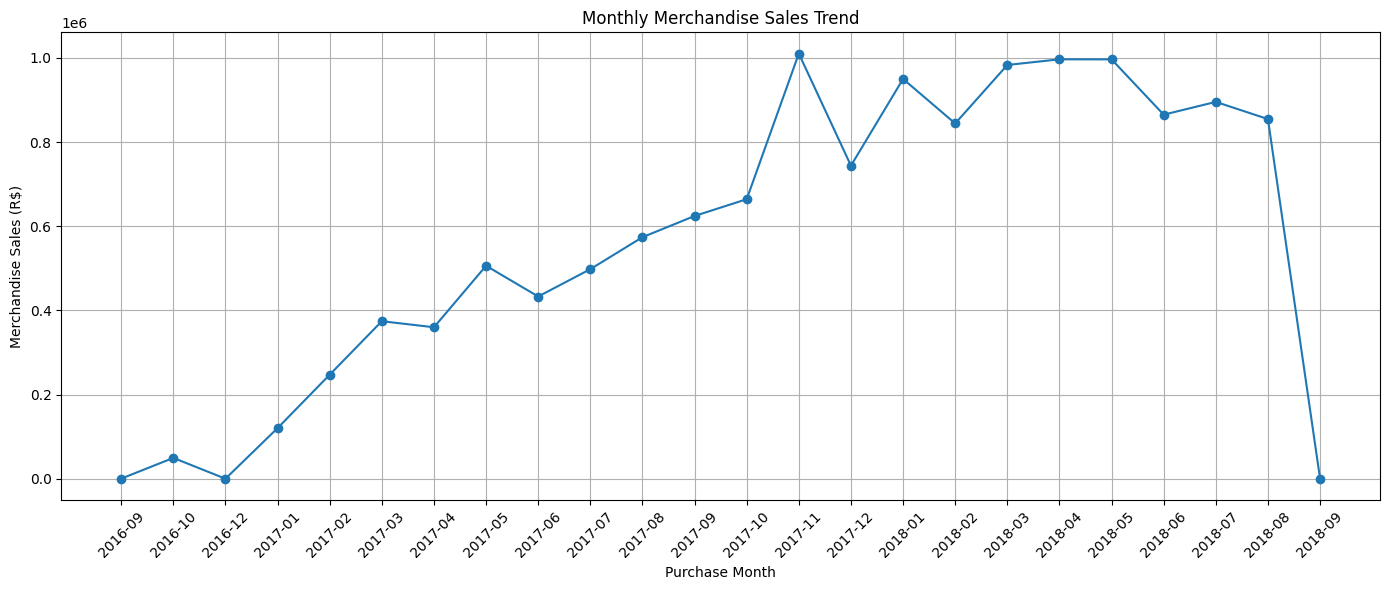

In [ ]:
plt.figure(figsize=(14, 6))

plt.plot(
    monthly_sales["purchase_month"],
    monthly_sales["merchandise_sales"],
    marker="o"
)

plt.title("Monthly Merchandise Sales Trend")
plt.xlabel("Purchase Month")
plt.ylabel("Merchandise Sales (R$)")
plt.xticks(rotation=45)
plt.grid(True)
plt.tight_layout()
plt.show()

In [ ]:
# Examine date coverage

print("========== DATASET DATE COVERAGE ==========")

print(
    "First purchase date:",
    sales["order_purchase_timestamp"].min()
)

print(
    "Last purchase date:",
    sales["order_purchase_timestamp"].max()
)

print("\n========== MONTHLY ORDER STATUS ==========")

selected_months = ["2016-09", "2016-12", "2018-09"]

for month in selected_months:

    month_data = sales[
        sales["purchase_month"].astype(str) == month
    ]

    print(f"\n{month}")
    print("Order items:", len(month_data))
    print("Unique orders:", month_data["order_id"].nunique())

    print("\nOrder statuses:")
    print(month_data["order_status"].value_counts())

========== DATASET DATE COVERAGE ==========
First purchase date: 2016-09-04 21:15:19
Last purchase date: 2018-09-03 09:06:57

========== MONTHLY ORDER STATUS ==========

2016-09
Order items: 6
Unique orders: 3

Order statuses:
order_status
delivered    3
shipped      2
canceled     1
Name: count, dtype: int64

2016-12
Order items: 1
Unique orders: 1

Order statuses:
order_status
delivered    1
Name: count, dtype: int64

2018-09
Order items: 1
Unique orders: 1

Order statuses:
order_status
shipped    1
Name: count, dtype: int64


In [ ]:
# Prepare product category analysis

product_sales = sales.merge(
    cleaned_datasets["products"][
        ["product_id", "product_category_name"]
    ],
    on="product_id",
    how="left"
)

# Attach English category names
product_sales = product_sales.merge(
    cleaned_datasets["category_translation"],
    on="product_category_name",
    how="left"
)

# Fill missing translated categories
product_sales["product_category_name_english"] = (
    product_sales["product_category_name_english"]
    .fillna("Unknown")
)

print("Product sales dataset shape:", product_sales.shape)

print("\nFirst five records:")

display(product_sales.head())

print("\nMissing values:")
print(product_sales.isnull().sum())

Product sales dataset shape: (112650, 13)

First five records:


,order_id,order_item_id,product_id,seller_id,shipping_limit_date,price,freight_value,order_purchase_timestamp,order_status,purchase_month,total_item_value,product_category_name,product_category_name_english
0,00010242fe8c5a6d1ba2dd792cb16214,1,4244733e06e7ecb4970a6e2683c13e61,48436dade18ac8b2bce089ec2a041202,2017-09-19 09:45:35,58.90,13.29,2017-09-13 08:59:02,delivered,2017-09,72.19,cool_stuff,cool_stuff
1,00018f77f2f0320c557190d7a144bdd3,1,e5f2d52b802189ee658865ca93d83a8f,dd7ddc04e1b6c2c614352b383efe2d36,2017-05-03 11:05:13,239.90,19.93,2017-04-26 10:53:06,delivered,2017-04,259.83,pet_shop,pet_shop
2,000229ec398224ef6ca0657da4fc703e,1,c777355d18b72b67abbeef9df44fd0fd,5b51032eddd242adc84c38acab88f23d,2018-01-18 14:48:30,199.00,17.87,2018-01-14 14:33:31,delivered,2018-01,216.87,moveis_decoracao,furniture_decor
3,00024acbcdf0a6daa1e931b038114c75,1,7634da152a4610f1595efa32f14722fc,9d7a1d34a5052409006425275ba1c2b4,2018-08-15 10:10:18,12.99,12.79,2018-08-08 10:00:35,delivered,2018-08,25.78,perfumaria,perfumery
4,00042b26cf59d7ce69dfabb4e55b4fd9,1,ac6c3623068f30de03045865e4e10089,df560393f3a51e74553ab94004ba5c87,2017-02-13 13:57:51,199.90,18.14,2017-02-04 13:57:51,delivered,2017-02,218.04,ferramentas_jardim,garden_tools



Missing values:
order_id                         0
order_item_id                    0
product_id                       0
seller_id                        0
shipping_limit_date              0
price                            0
freight_value                    0
order_purchase_timestamp         0
order_status                     0
purchase_month                   0
total_item_value                 0
product_category_name            0
product_category_name_english    0
dtype: int64


In [ ]:
# Analyse product category performance

category_performance = (
    product_sales.groupby("product_category_name_english")
    .agg(
        merchandise_sales=("price", "sum"),
        items_sold=("product_id", "count"),
        unique_products=("product_id", "nunique"),
        average_item_price=("price", "mean"),
        total_orders=("order_id", "nunique")
    )
    .reset_index()
)

# Sort categories by merchandise sales
category_performance = category_performance.sort_values(
    by="merchandise_sales",
    ascending=False
)

# Calculate percentage contribution
category_performance["sales_percentage"] = (
    category_performance["merchandise_sales"] /
    category_performance["merchandise_sales"].sum()
) * 100

print("========== TOP 15 PRODUCT CATEGORIES ==========")

display(category_performance.head(15).round(2))

========== TOP 15 PRODUCT CATEGORIES ==========


,product_category_name_english,merchandise_sales,items_sold,unique_products,average_item_price,total_orders,sales_percentage
44,health_beauty,1258681.34,9670,2444,130.16,8836,9.26
71,watches_gifts,1205005.68,5991,1329,201.14,5624,8.87
8,bed_bath_table,1036988.68,11115,3029,93.30,9417,7.63
66,sports_leisure,988048.97,8641,2867,114.34,7720,7.27
16,computers_accessories,911954.32,7827,1639,116.51,6689,6.71
40,furniture_decor,729762.49,8334,2657,87.56,6449,5.37
21,cool_stuff,635290.85,3796,789,167.36,3632,4.67
50,housewares,632248.66,6964,2335,90.79,5884,4.65
6,auto,592720.11,4235,1900,139.96,3897,4.36
43,garden_tools,485256.46,4347,753,111.63,3518,3.57


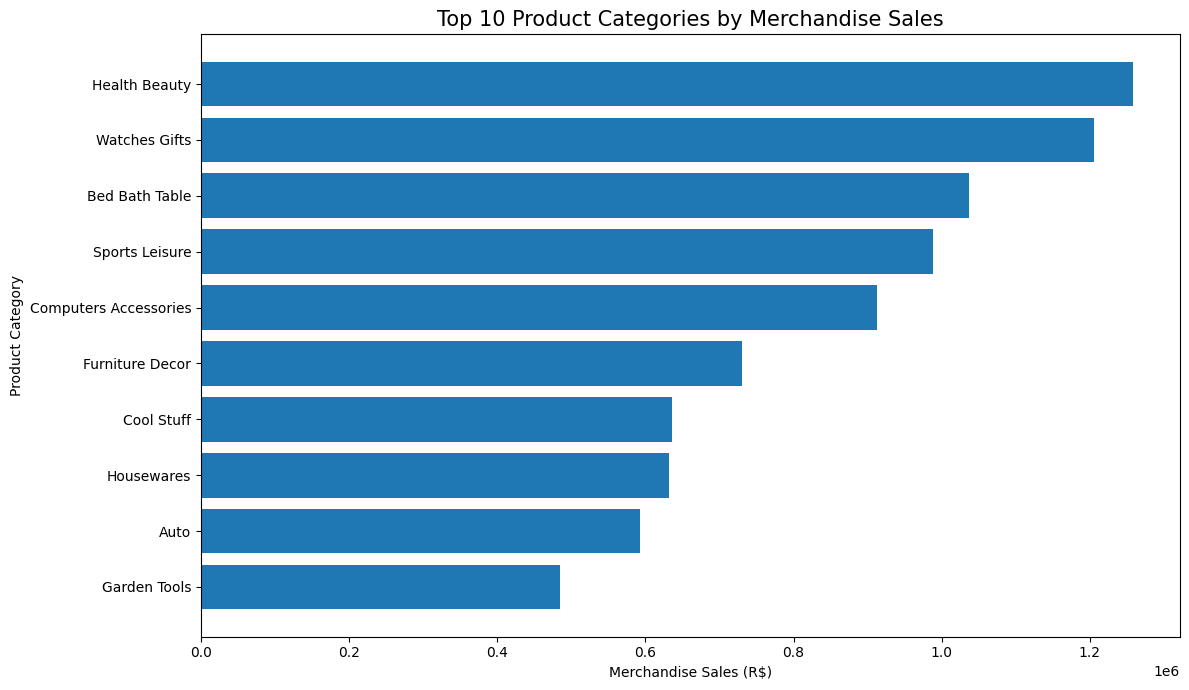

In [ ]:
# Select top 10 categories
top_10_categories = category_performance.head(10).copy()

# Make category names more readable
top_10_categories["category_label"] = (
    top_10_categories["product_category_name_english"]
    .str.replace("_", " ")
    .str.title()
)

# Create chart
plt.figure(figsize=(12, 7))

plt.barh(
    top_10_categories["category_label"],
    top_10_categories["merchandise_sales"]
)

plt.title(
    "Top 10 Product Categories by Merchandise Sales",
    fontsize=15
)

plt.xlabel("Merchandise Sales (R$)")
plt.ylabel("Product Category")

plt.gca().invert_yaxis()

plt.tight_layout()
plt.show()

In [ ]:
# Compare item quantity and merchandise sales

category_comparison = category_performance[
    [
        "product_category_name_english",
        "items_sold",
        "merchandise_sales",
        "average_item_price"
    ]
].copy()

# Calculate percentage of total items
category_comparison["quantity_percentage"] = (
    category_comparison["items_sold"] /
    category_comparison["items_sold"].sum()
) * 100

# Sort by quantity sold
category_comparison = category_comparison.sort_values(
    by="items_sold",
    ascending=False
)

print("========== TOP 15 CATEGORIES BY QUANTITY ==========")

display(category_comparison.head(15).round(2))

========== TOP 15 CATEGORIES BY QUANTITY ==========


,product_category_name_english,items_sold,merchandise_sales,average_item_price,quantity_percentage
8,bed_bath_table,11115,1036988.68,93.30,9.87
44,health_beauty,9670,1258681.34,130.16,8.58
66,sports_leisure,8641,988048.97,114.34,7.67
40,furniture_decor,8334,729762.49,87.56,7.40
16,computers_accessories,7827,911954.32,116.51,6.95
50,housewares,6964,632248.66,90.79,6.18
71,watches_gifts,5991,1205005.68,201.14,5.32
69,telephony,4545,323667.53,71.21,4.03
43,garden_tools,4347,485256.46,111.63,3.86
6,auto,4235,592720.11,139.96,3.76


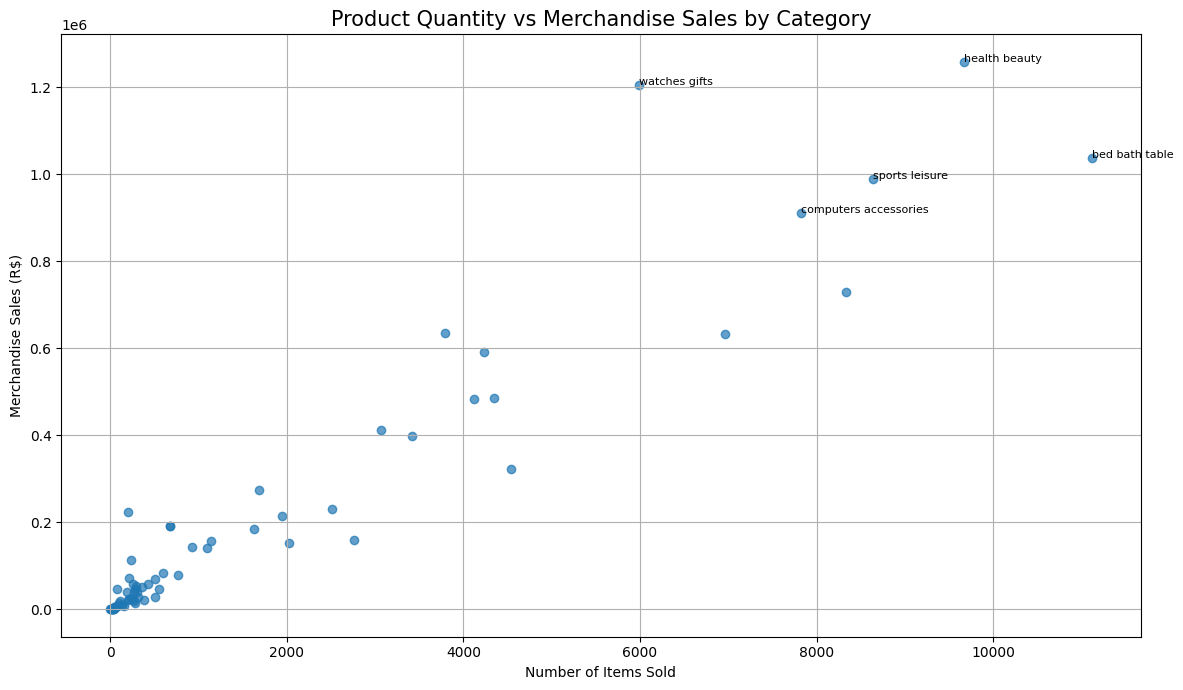

In [ ]:
# Scatter plot: Quantity vs Merchandise Sales

plt.figure(figsize=(12, 7))

plt.scatter(
    category_performance["items_sold"],
    category_performance["merchandise_sales"],
    alpha=0.7
)

plt.title(
    "Product Quantity vs Merchandise Sales by Category",
    fontsize=15
)

plt.xlabel("Number of Items Sold")
plt.ylabel("Merchandise Sales (R$)")

# Label the five leading categories by sales
top_five = category_performance.head(5)

for _, row in top_five.iterrows():
    plt.annotate(
        row["product_category_name_english"].replace("_", " "),
        (row["items_sold"], row["merchandise_sales"]),
        fontsize=8
    )

plt.grid(True)
plt.tight_layout()
plt.show()

In [ ]:
# Prepare customer purchasing dataset

customer_sales = sales.merge(
    cleaned_datasets["orders"][
        ["order_id", "customer_id"]
    ],
    on="order_id",
    how="left"
)

# Attach customer location
customer_sales = customer_sales.merge(
    cleaned_datasets["customers"][
        ["customer_id", "customer_city", "customer_state"]
    ],
    on="customer_id",
    how="left"
)

print("Customer sales dataset shape:", customer_sales.shape)

print("\nFirst five records:")

display(customer_sales.head())

print("\nMissing values:")

print(customer_sales.isnull().sum())

Customer sales dataset shape: (112650, 14)

First five records:


,order_id,order_item_id,product_id,seller_id,shipping_limit_date,price,freight_value,order_purchase_timestamp,order_status,purchase_month,total_item_value,customer_id,customer_city,customer_state
0,00010242fe8c5a6d1ba2dd792cb16214,1,4244733e06e7ecb4970a6e2683c13e61,48436dade18ac8b2bce089ec2a041202,2017-09-19 09:45:35,58.90,13.29,2017-09-13 08:59:02,delivered,2017-09,72.19,3ce436f183e68e07877b285a838db11a,campos dos goytacazes,RJ
1,00018f77f2f0320c557190d7a144bdd3,1,e5f2d52b802189ee658865ca93d83a8f,dd7ddc04e1b6c2c614352b383efe2d36,2017-05-03 11:05:13,239.90,19.93,2017-04-26 10:53:06,delivered,2017-04,259.83,f6dd3ec061db4e3987629fe6b26e5cce,santa fe do sul,SP
2,000229ec398224ef6ca0657da4fc703e,1,c777355d18b72b67abbeef9df44fd0fd,5b51032eddd242adc84c38acab88f23d,2018-01-18 14:48:30,199.00,17.87,2018-01-14 14:33:31,delivered,2018-01,216.87,6489ae5e4333f3693df5ad4372dab6d3,para de minas,MG
3,00024acbcdf0a6daa1e931b038114c75,1,7634da152a4610f1595efa32f14722fc,9d7a1d34a5052409006425275ba1c2b4,2018-08-15 10:10:18,12.99,12.79,2018-08-08 10:00:35,delivered,2018-08,25.78,d4eb9395c8c0431ee92fce09860c5a06,atibaia,SP
4,00042b26cf59d7ce69dfabb4e55b4fd9,1,ac6c3623068f30de03045865e4e10089,df560393f3a51e74553ab94004ba5c87,2017-02-13 13:57:51,199.90,18.14,2017-02-04 13:57:51,delivered,2017-02,218.04,58dbd0b2d70206bf40e62cd34e84d795,varzea paulista,SP



Missing values:
order_id                    0
order_item_id               0
product_id                  0
seller_id                   0
shipping_limit_date         0
price                       0
freight_value               0
order_purchase_timestamp    0
order_status                0
purchase_month              0
total_item_value            0
customer_id                 0
customer_city               0
customer_state              0
dtype: int64


In [ ]:
# Customer purchasing frequency

customer_orders = (
    customer_sales.groupby("customer_id")
    .agg(
        total_orders=("order_id", "nunique"),
        merchandise_sales=("price", "sum"),
        items_purchased=("product_id", "count")
    )
    .reset_index()
)

# Classify customers by purchase frequency
customer_orders["customer_type"] = np.where(
    customer_orders["total_orders"] > 1,
    "Repeat Customer",
    "One-time Customer"
)

# Summarise customer types
customer_summary = (
    customer_orders.groupby("customer_type")
    .agg(
        customers=("customer_id", "nunique"),
        total_orders=("total_orders", "sum"),
        merchandise_sales=("merchandise_sales", "sum")
    )
    .reset_index()
)

# Calculate percentage of customers
customer_summary["customer_percentage"] = (
    customer_summary["customers"] /
    customer_summary["customers"].sum()
) * 100

print("========== CUSTOMER PURCHASING FREQUENCY ==========")

display(customer_summary.round(2))

========== CUSTOMER PURCHASING FREQUENCY ==========


,customer_type,customers,total_orders,merchandise_sales,customer_percentage
0,One-time Customer,98666,98666,13591643.7,100.0


In [ ]:
# Attach the actual unique customer identifier

customer_sales = customer_sales.merge(
    cleaned_datasets["customers"][
        ["customer_id", "customer_unique_id"]
    ],
    on="customer_id",
    how="left"
)

# Calculate purchasing frequency per unique customer
customer_orders = (
    customer_sales.groupby("customer_unique_id")
    .agg(
        total_orders=("order_id", "nunique"),
        merchandise_sales=("price", "sum"),
        items_purchased=("product_id", "count")
    )
    .reset_index()
)

# Classify customers
customer_orders["customer_type"] = np.where(
    customer_orders["total_orders"] > 1,
    "Repeat Customer",
    "One-time Customer"
)

# Summarise purchasing behaviour
customer_summary = (
    customer_orders.groupby("customer_type")
    .agg(
        customers=("customer_unique_id", "nunique"),
        total_orders=("total_orders", "sum"),
        merchandise_sales=("merchandise_sales", "sum")
    )
    .reset_index()
)

customer_summary["customer_percentage"] = (
    customer_summary["customers"] /
    customer_summary["customers"].sum()
) * 100

print("========== CORRECTED CUSTOMER PURCHASING FREQUENCY ==========")

display(customer_summary.round(2))

========== CORRECTED CUSTOMER PURCHASING FREQUENCY ==========


,customer_type,customers,total_orders,merchandise_sales,customer_percentage
0,One-time Customer,92507,92507,12828351.84,96.95
1,Repeat Customer,2913,6159,763291.86,3.05


In [ ]:
# Calculate customer value

customer_value = customer_orders.groupby("customer_type").agg(
    average_orders_per_customer=("total_orders", "mean"),
    average_customer_sales=("merchandise_sales", "mean"),
    highest_customer_sales=("merchandise_sales", "max")
).reset_index()

print("========== CUSTOMER VALUE ANALYSIS ==========")

display(customer_value.round(2))

========== CUSTOMER VALUE ANALYSIS ==========


,customer_type,average_orders_per_customer,average_customer_sales,highest_customer_sales
0,One-time Customer,1.00,138.67,13440.0
1,Repeat Customer,2.11,262.03,7388.0


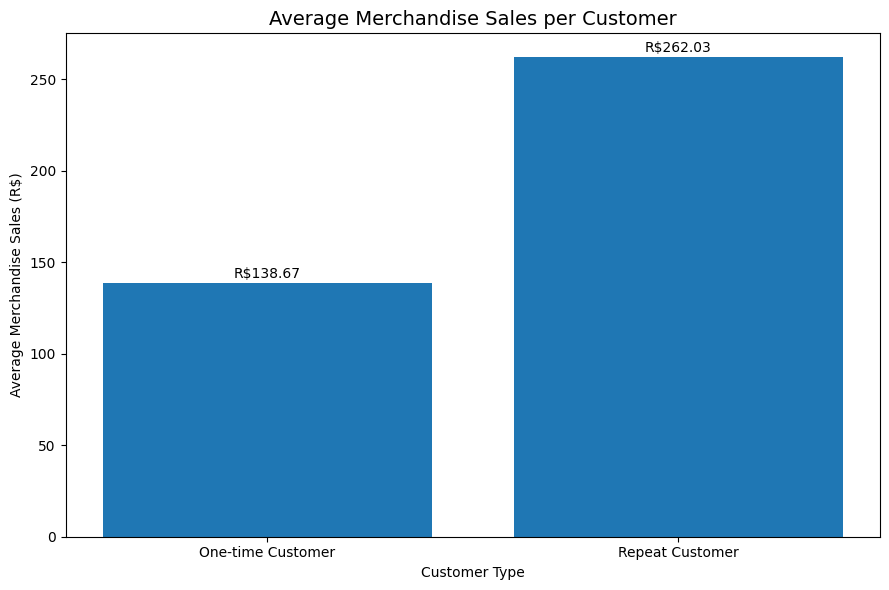

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(9, 6))

plt.bar(
    customer_value["customer_type"],
    customer_value["average_customer_sales"]
)

plt.title("Average Merchandise Sales per Customer", fontsize=14)
plt.xlabel("Customer Type")
plt.ylabel("Average Merchandise Sales (R$)")

for index, value in enumerate(
    customer_value["average_customer_sales"]
):
    plt.text(index, value + 3, f"R${value:,.2f}", ha="center")

plt.tight_layout()
plt.show()

In [ ]:
# Geographical sales analysis by state

state_sales = (
    customer_sales.groupby("customer_state")
    .agg(
        merchandise_sales=("price", "sum"),
        total_orders=("order_id", "nunique"),
        items_sold=("product_id", "count"),
        unique_customers=("customer_id", "nunique")
    )
    .reset_index()
)

# Calculate percentage contribution to total sales
state_sales["sales_percentage"] = (
    state_sales["merchandise_sales"] /
    state_sales["merchandise_sales"].sum()
) * 100

# Arrange states from highest to lowest sales
state_sales = state_sales.sort_values(
    by="merchandise_sales",
    ascending=False
)

print("========== SALES PERFORMANCE BY STATE ==========")

display(state_sales.round(2))

========== SALES PERFORMANCE BY STATE ==========


,customer_state,merchandise_sales,total_orders,items_sold,unique_customers,sales_percentage
25,SP,5202955.05,41375,47449,41375,38.28
18,RJ,1824092.67,12762,14579,12762,13.42
10,MG,1585308.03,11544,13129,11544,11.66
22,RS,750304.02,5432,6235,5432,5.52
17,PR,683083.76,4998,5740,4998,5.03
23,SC,520553.34,3612,4176,3612,3.83
4,BA,511349.99,3358,3799,3358,3.76
6,DF,302603.94,2125,2406,2125,2.23
8,GO,294591.95,2007,2333,2007,2.17
7,ES,275037.31,2025,2256,2025,2.02


In [ ]:
# Geographical sales analysis by city

city_sales = (
    customer_sales.groupby(
        ["customer_state", "customer_city"]
    )
    .agg(
        merchandise_sales=("price", "sum"),
        total_orders=("order_id", "nunique"),
        items_sold=("product_id", "count"),
        unique_customers=("customer_unique_id", "nunique")
    )
    .reset_index()
)

# Calculate percentage contribution
city_sales["sales_percentage"] = (
    city_sales["merchandise_sales"] /
    city_sales["merchandise_sales"].sum()
) * 100

# Rank cities by merchandise sales
city_sales = city_sales.sort_values(
    by="merchandise_sales",
    ascending=False
)

# Display top 15 cities
top_15_cities = city_sales.head(15)

print("========== TOP 15 CITIES BY MERCHANDISE SALES ==========")

display(top_15_cities.round(2))

========== TOP 15 CITIES BY MERCHANDISE SALES ==========


,customer_state,customer_city,merchandise_sales,total_orders,items_sold,unique_customers,sales_percentage
4166,SP,sao paulo,1914924.54,15402,17808,14865,14.09
2782,RJ,rio de janeiro,992538.86,6834,7837,6576,7.30
1059,MG,belo horizonte,355611.13,2750,3144,2654,2.62
600,DF,brasilia,301920.25,2116,2392,2056,2.22
2402,PR,curitiba,211738.06,1510,1751,1455,1.56
3201,RS,porto alegre,190562.08,1372,1612,1320,1.40
3720,SP,campinas,187844.53,1429,1654,1386,1.38
371,BA,salvador,181104.42,1238,1412,1202,1.33
3827,SP,guarulhos,144268.39,1178,1329,1143,1.06
2753,RJ,niteroi,117907.12,845,980,807,0.87


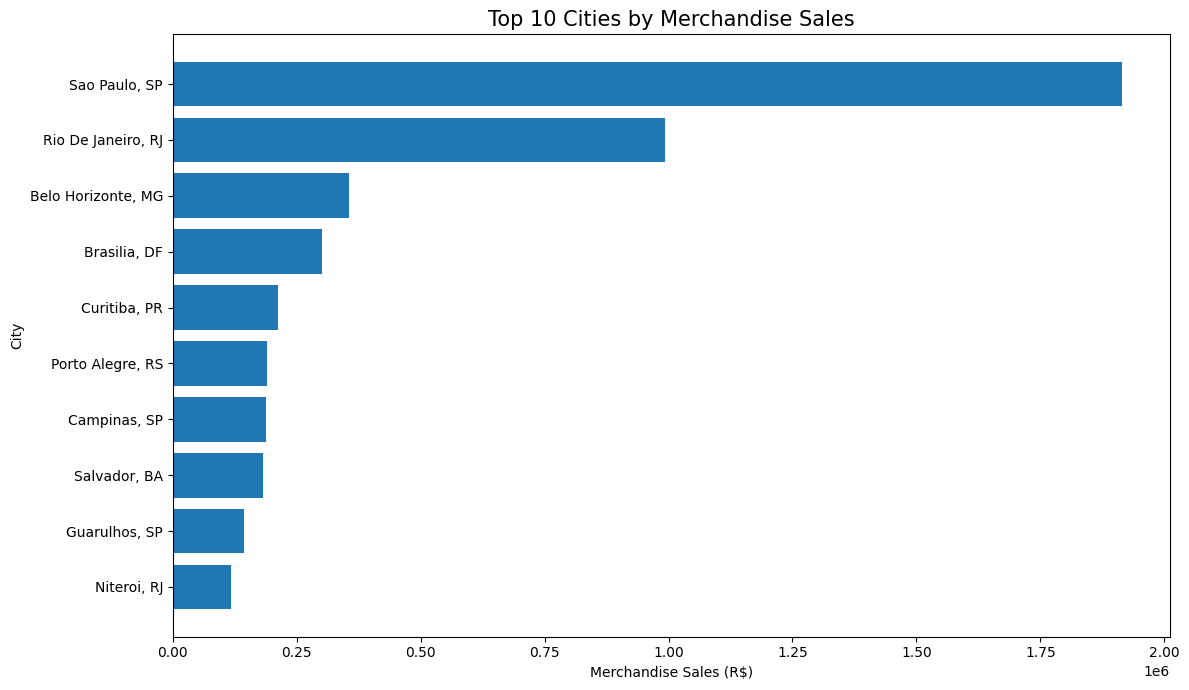

In [ ]:
import matplotlib.pyplot as plt

# Select top 10 cities
top_10_cities = city_sales.head(10).copy()

# Combine city and state for clear labels
top_10_cities["city_label"] = (
    top_10_cities["customer_city"].str.title()
    + ", "
    + top_10_cities["customer_state"]
)

# Create chart
plt.figure(figsize=(12, 7))

plt.barh(
    top_10_cities["city_label"],
    top_10_cities["merchandise_sales"]
)

plt.title("Top 10 Cities by Merchandise Sales", fontsize=15)
plt.xlabel("Merchandise Sales (R$)")
plt.ylabel("City")

plt.gca().invert_yaxis()

plt.tight_layout()
plt.show()

In [ ]:
# Prepare delivery performance dataset

delivery = cleaned_datasets["orders"][
    [
        "order_id",
        "customer_id",
        "order_status",
        "order_purchase_timestamp",
        "order_delivered_customer_date",
        "order_estimated_delivery_date"
    ]
].copy()

# Attach customer geographical information
delivery = delivery.merge(
    cleaned_datasets["customers"][
        ["customer_id", "customer_city", "customer_state"]
    ],
    on="customer_id",
    how="left"
)

print("========== DELIVERY DATASET ==========")

print("Dataset shape:", delivery.shape)

print("\nFirst five records:")

display(delivery.head())

print("\nMissing values:")

display(delivery.isnull().sum())

========== DELIVERY DATASET ==========
Dataset shape: (99441, 8)

First five records:


,order_id,customer_id,order_status,order_purchase_timestamp,order_delivered_customer_date,order_estimated_delivery_date,customer_city,customer_state
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-10 21:25:13,2017-10-18,sao paulo,SP
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-08-07 15:27:45,2018-08-13,barreiras,BA
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-17 18:06:29,2018-09-04,vianopolis,GO
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-12-02 00:28:42,2017-12-15,sao goncalo do amarante,RN
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-16 18:17:02,2018-02-26,santo andre,SP



Missing values:


,0
order_id,0
customer_id,0
order_status,0
order_purchase_timestamp,0
order_delivered_customer_date,2965
order_estimated_delivery_date,0
customer_city,0
customer_state,0


In [ ]:
# Filter successfully delivered orders

delivered_orders = delivery[
    (delivery["order_status"] == "delivered") &
    (delivery["order_delivered_customer_date"].notna())
].copy()

# Calculate actual delivery time in days

delivered_orders["delivery_time_days"] = (
    delivered_orders["order_delivered_customer_date"] -
    delivered_orders["order_purchase_timestamp"]
).dt.total_seconds() / 86400

# Calculate delivery time statistics

delivery_summary = delivered_orders["delivery_time_days"].describe()

print("========== DELIVERY TIME SUMMARY ==========")

display(delivery_summary.round(2))

print("\nTotal delivered orders:", len(delivered_orders))

========== DELIVERY TIME SUMMARY ==========


,delivery_time_days
count,96470.00
mean,12.56
std,9.55
min,0.53
25%,6.77
50%,10.22
75%,15.72
max,209.63



Total delivered orders: 96470


In [ ]:
# Compare actual and estimated delivery dates

delivered_orders["actual_delivery_day"] = (
    delivered_orders["order_delivered_customer_date"].dt.normalize()
)

delivered_orders["estimated_delivery_day"] = (
    delivered_orders["order_estimated_delivery_date"].dt.normalize()
)

# Classify delivery performance

delivered_orders["delivery_performance"] = np.where(
    delivered_orders["actual_delivery_day"] <=
    delivered_orders["estimated_delivery_day"],
    "On Time",
    "Delayed"
)

# Summarise delivery performance

delivery_performance = (
    delivered_orders.groupby("delivery_performance")
    .agg(
        total_orders=("order_id", "nunique")
    )
    .reset_index()
)

# Calculate percentages

delivery_performance["percentage"] = (
    delivery_performance["total_orders"] /
    delivery_performance["total_orders"].sum()
) * 100

print("========== ON-TIME DELIVERY PERFORMANCE ==========")

display(delivery_performance.round(2))

========== ON-TIME DELIVERY PERFORMANCE ==========


,delivery_performance,total_orders,percentage
0,Delayed,6534,6.77
1,On Time,89936,93.23


In [ ]:
# Analyse average delivery time by state

state_delivery = (
    delivered_orders.groupby("customer_state")
    .agg(
        total_orders=("order_id", "nunique"),
        average_delivery_days=("delivery_time_days", "mean"),
        median_delivery_days=("delivery_time_days", "median")
    )
    .reset_index()
)

# Rank states by average delivery time
state_delivery = state_delivery.sort_values(
    by="average_delivery_days",
    ascending=False
)

print("========== DELIVERY PERFORMANCE BY STATE ==========")

display(state_delivery.round(2))

========== DELIVERY PERFORMANCE BY STATE ==========


,customer_state,total_orders,average_delivery_days,median_delivery_days
21,RR,41,29.39,25.01
3,AP,67,27.19,24.35
2,AM,145,26.43,25.88
1,AL,397,24.54,22.33
13,PA,946,23.77,21.08
9,MA,717,21.57,19.19
24,SE,335,21.52,18.01
5,CE,1279,21.27,18.21
0,AC,80,21.04,18.36
14,PB,517,20.43,18.15


In [ ]:
# Prepare customer review data

delivery_reviews = delivered_orders.merge(
    cleaned_datasets["reviews"][
        ["order_id", "review_score"]
    ],
    on="order_id",
    how="left"
)

# Calculate customer satisfaction by delivery performance

satisfaction_by_delivery = (
    delivery_reviews.groupby("delivery_performance")
    .agg(
        total_orders=("order_id", "nunique"),
        reviewed_orders=("review_score", "count"),
        average_review_score=("review_score", "mean")
    )
    .reset_index()
)

print("========== DELIVERY AND CUSTOMER SATISFACTION ==========")

display(satisfaction_by_delivery.round(2))

========== DELIVERY AND CUSTOMER SATISFACTION ==========


,delivery_performance,total_orders,reviewed_orders,average_review_score
0,Delayed,6534,6409,2.27
1,On Time,89936,89944,4.29


In [ ]:
# Check review records and unique orders

reviews = cleaned_datasets["reviews"]

print("========== REVIEW DATA VALIDATION ==========")

print("Total review records:", len(reviews))

print("Unique reviewed orders:", reviews["order_id"].nunique())

print(
    "Orders with multiple review records:",
    reviews["order_id"].duplicated().sum()
)

print(
    "Unique review IDs:",
    reviews["review_id"].nunique()
)

========== REVIEW DATA VALIDATION ==========
Total review records: 99224
Unique reviewed orders: 98673
Orders with multiple review records: 551
Unique review IDs: 98410


In [ ]:
# Calculate one average review score per order

order_reviews = (
    cleaned_datasets["reviews"]
    .groupby("order_id")
    .agg(
        average_review_score=("review_score", "mean"),
        review_records=("review_score", "count")
    )
    .reset_index()
)

# Merge with delivered orders
corrected_delivery_reviews = delivered_orders.merge(
    order_reviews[
        ["order_id", "average_review_score"]
    ],
    on="order_id",
    how="left"
)

# Compare customer satisfaction by delivery performance
corrected_satisfaction = (
    corrected_delivery_reviews.groupby("delivery_performance")
    .agg(
        total_orders=("order_id", "nunique"),
        reviewed_orders=("average_review_score", "count"),
        average_review_score=("average_review_score", "mean")
    )
    .reset_index()
)

print("========== CORRECTED DELIVERY AND CUSTOMER SATISFACTION ==========")

display(corrected_satisfaction.round(2))

========== CORRECTED DELIVERY AND CUSTOMER SATISFACTION ==========


,delivery_performance,total_orders,reviewed_orders,average_review_score
0,Delayed,6534,6381,2.27
1,On Time,89936,89443,4.29


In [ ]:
# Prepare payment dataset

payments = cleaned_datasets["payments"].copy()

print("========== PAYMENT DATASET ==========")

print("Dataset shape:", payments.shape)

print("\nFirst five records:")

display(payments.head())

print("\nPayment method distribution:")

display(payments["payment_type"].value_counts())

print("\nMissing values:")

display(payments.isnull().sum())

========== PAYMENT DATASET ==========
Dataset shape: (103886, 5)

First five records:


,order_id,payment_sequential,payment_type,payment_installments,payment_value
0,b81ef226f3fe1789b1e8b2acac839d17,1,credit_card,8,99.33
1,a9810da82917af2d9aefd1278f1dcfa0,1,credit_card,1,24.39
2,25e8ea4e93396b6fa0d3dd708e76c1bd,1,credit_card,1,65.71
3,ba78997921bbcdc1373bb41e913ab953,1,credit_card,8,107.78
4,42fdf880ba16b47b59251dd489d4441a,1,credit_card,2,128.45



Payment method distribution:


,count
payment_type,
credit_card,76795
boleto,19784
voucher,5775
debit_card,1529
not_defined,3



Missing values:


,0
order_id,0
payment_sequential,0
payment_type,0
payment_installments,0
payment_value,0


In [ ]:
# Analyse payment methods

payment_performance = (
    payments.groupby("payment_type")
    .agg(
        payment_records=("order_id", "count"),
        unique_orders=("order_id", "nunique"),
        total_payment_value=("payment_value", "sum"),
        average_payment_value=("payment_value", "mean")
    )
    .reset_index()
)

payment_performance["payment_percentage"] = (
    payment_performance["payment_records"] /
    payment_performance["payment_records"].sum()
) * 100

payment_performance["value_percentage"] = (
    payment_performance["total_payment_value"] /
    payment_performance["total_payment_value"].sum()
) * 100

payment_performance = payment_performance.sort_values(
    by="total_payment_value",
    ascending=False
)

print("========== PAYMENT METHOD PERFORMANCE ==========")

display(payment_performance.round(2))

========== PAYMENT METHOD PERFORMANCE ==========


,payment_type,payment_records,unique_orders,total_payment_value,average_payment_value,payment_percentage,value_percentage
1,credit_card,76795,76505,12542084.19,163.32,73.92,78.34
0,boleto,19784,19784,2869361.27,145.03,19.04,17.92
4,voucher,5775,3866,379436.87,65.70,5.56,2.37
2,debit_card,1529,1528,217989.79,142.57,1.47,1.36
3,not_defined,3,3,0.00,0.00,0.00,0.00


In [ ]:
# Analyse payment installment behaviour

installment_analysis = (
    payments.groupby("payment_installments")
    .agg(
        payment_records=("order_id", "count"),
        unique_orders=("order_id", "nunique"),
        total_payment_value=("payment_value", "sum"),
        average_payment_value=("payment_value", "mean")
    )
    .reset_index()
)

installment_analysis["percentage_of_records"] = (
    installment_analysis["payment_records"] /
    installment_analysis["payment_records"].sum()
) * 100

installment_analysis = installment_analysis.sort_values(
    by="payment_installments"
)

print("========== PAYMENT INSTALLMENT ANALYSIS ==========")

display(installment_analysis.round(2))

========== PAYMENT INSTALLMENT ANALYSIS ==========


,payment_installments,payment_records,unique_orders,total_payment_value,average_payment_value,percentage_of_records
0,0,2,2,188.63,94.32,0.00
1,1,52546,49060,5907233.36,112.42,50.58
2,2,12413,12389,1579283.03,127.23,11.95
3,3,10461,10443,1491103.80,142.54,10.07
4,4,7098,7088,1163907.61,163.98,6.83
5,5,5239,5234,961174.30,183.47,5.04
6,6,3920,3916,822611.81,209.85,3.77
7,7,1626,1623,305157.39,187.67,1.57
8,8,4268,4253,1313423.34,307.74,4.11
9,9,644,644,131015.92,203.44,0.62


In [ ]:
# Compare installment behaviour across payment methods

payment_method_installments = (
    payments.groupby("payment_type")
    .agg(
        payment_records=("order_id", "count"),
        average_installments=("payment_installments", "mean"),
        median_installments=("payment_installments", "median"),
        maximum_installments=("payment_installments", "max"),
        total_payment_value=("payment_value", "sum")
    )
    .reset_index()
)

payment_method_installments = payment_method_installments.sort_values(
    by="total_payment_value",
    ascending=False
)

print("========== INSTALLMENTS BY PAYMENT METHOD ==========")

display(payment_method_installments.round(2))

========== INSTALLMENTS BY PAYMENT METHOD ==========


,payment_type,payment_records,average_installments,median_installments,maximum_installments,total_payment_value
1,credit_card,76795,3.51,3.0,24,12542084.19
0,boleto,19784,1.00,1.0,1,2869361.27
4,voucher,5775,1.00,1.0,1,379436.87
2,debit_card,1529,1.00,1.0,1,217989.79
3,not_defined,3,1.00,1.0,1,0.00


In [ ]:
# Analyse customer review scores

reviews = cleaned_datasets["reviews"].copy()

review_distribution = (
    reviews.groupby("review_score")
    .agg(
        review_records=("review_id", "count"),
        unique_orders=("order_id", "nunique")
    )
    .reset_index()
)

review_distribution["percentage"] = (
    review_distribution["review_records"] /
    review_distribution["review_records"].sum()
) * 100

print("========== CUSTOMER REVIEW SCORE DISTRIBUTION ==========")

display(review_distribution.round(2))

print("\nAverage review score:")

print(round(reviews["review_score"].mean(), 2))

print("\nTotal review records:", len(reviews))

========== CUSTOMER REVIEW SCORE DISTRIBUTION ==========


,review_score,review_records,unique_orders,percentage
0,1,11424,11393,11.51
1,2,3151,3148,3.18
2,3,8179,8160,8.24
3,4,19142,19098,19.29
4,5,57328,57076,57.78



Average review score:
4.09

Total review records: 99224


In [ ]:
# Classify customer reviews

reviews["review_category"] = np.select(
    [
        reviews["review_score"] >= 4,
        reviews["review_score"] == 3,
        reviews["review_score"] <= 2
    ],
    [
        "Positive",
        "Neutral",
        "Negative"
    ],
    default="Unclassified"
)

# Summarise review categories

review_sentiment = (
    reviews.groupby("review_category")
    .agg(
        review_records=("review_id", "count"),
        unique_orders=("order_id", "nunique")
    )
    .reset_index()
)

review_sentiment["percentage"] = (
    review_sentiment["review_records"] /
    review_sentiment["review_records"].sum()
) * 100

print("========== CUSTOMER REVIEW SENTIMENT ==========")

display(review_sentiment.round(2))

========== CUSTOMER REVIEW SENTIMENT ==========


,review_category,review_records,unique_orders,percentage
0,Negative,14575,14533,14.69
1,Neutral,8179,8160,8.24
2,Positive,76470,76120,77.07


In [ ]:
# Calculate one average review score per order

order_review_scores = (
    reviews.groupby("order_id")
    .agg(
        review_score=("review_score", "mean")
    )
    .reset_index()
)

# Connect order reviews to purchased products

category_reviews = sales.merge(
    order_review_scores,
    on="order_id",
    how="inner"
)

category_reviews = category_reviews.merge(
    cleaned_datasets["products"][
        ["product_id", "product_category_name"]
    ],
    on="product_id",
    how="left"
)

category_reviews = category_reviews.merge(
    cleaned_datasets["category_translation"],
    on="product_category_name",
    how="left"
)

category_reviews["product_category_name_english"] = (
    category_reviews["product_category_name_english"]
    .fillna("Unknown")
)

# Calculate customer satisfaction by category

category_satisfaction = (
    category_reviews.groupby("product_category_name_english")
    .agg(
        average_review_score=("review_score", "mean"),
        reviewed_items=("product_id", "count"),
        unique_orders=("order_id", "nunique")
    )
    .reset_index()
)

category_satisfaction = category_satisfaction.sort_values(
    by="average_review_score",
    ascending=False
)

print("========== CUSTOMER SATISFACTION BY PRODUCT CATEGORY ==========")

display(category_satisfaction.head(15).round(2))

========== CUSTOMER SATISFACTION BY PRODUCT CATEGORY ==========


,product_category_name_english,average_review_score,reviewed_items,unique_orders
12,cds_dvds_musicals,4.64,14,12
30,fashion_childrens_clothes,4.50,8,8
9,books_general_interest,4.45,549,508
23,costruction_tools_tools,4.44,99,94
36,flowers,4.42,31,28
10,books_imported,4.40,60,53
11,books_technical,4.36,264,257
54,luggage_accessories,4.32,1088,1030
38,food_drink,4.31,277,226
65,small_appliances_home_oven_and_coffee,4.30,76,75


In [ ]:
# Identify the 15 lowest-rated product categories

lowest_rated_categories = category_satisfaction.sort_values(
    by="average_review_score",
    ascending=True
).head(15)

print("========== LOWEST-RATED PRODUCT CATEGORIES ==========")

display(lowest_rated_categories.round(2))

========== LOWEST-RATED PRODUCT CATEGORIES ==========


,product_category_name_english,average_review_score,reviewed_items,unique_orders
62,security_and_services,2.50,2,2
24,diapers_and_hygiene,3.26,39,27
58,office_furniture,3.49,1677,1263
47,home_comfort_2,3.63,27,23
31,fashion_male_clothing,3.64,131,111
35,fixed_telephony,3.68,261,214
59,party_supplies,3.77,43,39
28,fashio_female_clothing,3.78,48,39
42,furniture_mattress_and_upholstery,3.82,38,38
0,Unknown,3.83,1613,1461


In [ ]:

import os
import zipfile
import pandas as pd

# Create export folder
export_folder = "/content/olist_final_exports"
os.makedirs(export_folder, exist_ok=True)

# Collect available analysis tables
analysis_tables = {
    "monthly_sales": monthly_sales,
    "category_performance": category_performance,
    "customer_summary": customer_summary,
    "customer_value": customer_value,
    "state_sales": state_sales,
    "city_sales": city_sales,
    "delivery_performance": delivery_performance,
    "state_delivery": state_delivery,
    "satisfaction_by_delivery": corrected_satisfaction,
    "payment_performance": payment_performance,
    "installment_analysis": installment_analysis,
    "payment_method_installments": payment_method_installments,
    "review_distribution": review_distribution,
    "review_sentiment": review_sentiment,
    "category_satisfaction": category_satisfaction,
    "lowest_rated_categories": lowest_rated_categories,
    "order_status_analysis": order_status_analysis,
    "seller_performance": seller_performance,
    "credit_card_installments": credit_card_installments
}

# Export analysis tables
for name, df in analysis_tables.items():
    df.to_csv(
        os.path.join(export_folder, f"{name}.csv"),
        index=False
    )

# Export cleaned datasets
for name, df in cleaned_datasets.items():
    df.to_csv(
        os.path.join(export_folder, f"cleaned_{name}.csv"),
        index=False
    )

# Create ZIP archive
zip_path = "/content/olist_final_analysis.zip"

with zipfile.ZipFile(zip_path, "w", zipfile.ZIP_DEFLATED) as archive:
    for filename in os.listdir(export_folder):
        archive.write(
            os.path.join(export_folder, filename),
            arcname=filename
        )

print("========== FINAL EXPORT SUMMARY ==========")
print("Analysis tables exported:", len(analysis_tables))
print("Cleaned datasets exported:", len(cleaned_datasets))
print("Total CSV files:", len(analysis_tables) + len(cleaned_datasets))
print("ZIP file created:", zip_path)

from google.colab import files
files.download(zip_path)


========== FINAL EXPORT SUMMARY ==========
Analysis tables exported: 19
Cleaned datasets exported: 9
Total CSV files: 28
ZIP file created: /content/olist_final_analysis.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

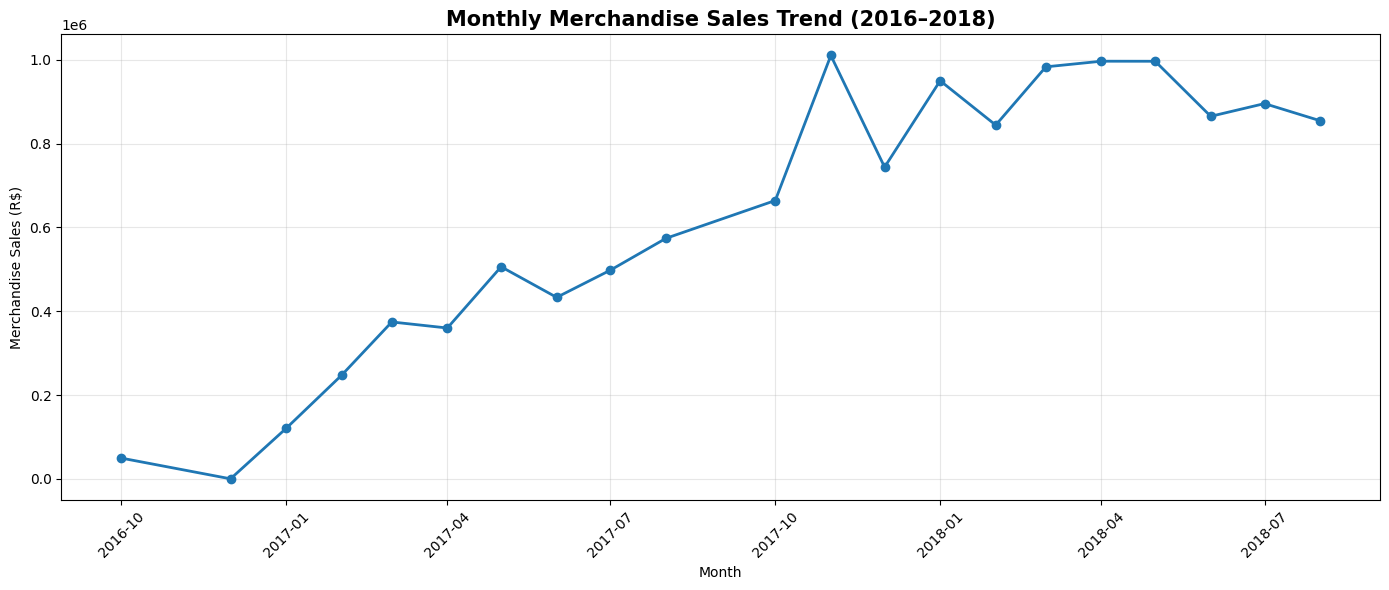

In [ ]:

import matplotlib.pyplot as plt
import pandas as pd

# Prepare monthly sales data
monthly_chart = monthly_sales.copy()

monthly_chart["purchase_month"] = (
    pd.to_datetime(monthly_chart["purchase_month"].astype(str))
)

# Exclude incomplete first and last months
monthly_chart = monthly_chart[
    ~monthly_chart["purchase_month"].dt.month.isin([9])
].copy()

# Create line chart
plt.figure(figsize=(14, 6))

plt.plot(
    monthly_chart["purchase_month"],
    monthly_chart["merchandise_sales"],
    marker="o",
    linewidth=2
)

plt.title(
    "Monthly Merchandise Sales Trend (2016–2018)",
    fontsize=15,
    fontweight="bold"
)

plt.xlabel("Month")
plt.ylabel("Merchandise Sales (R$)")

plt.xticks(rotation=45)
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()


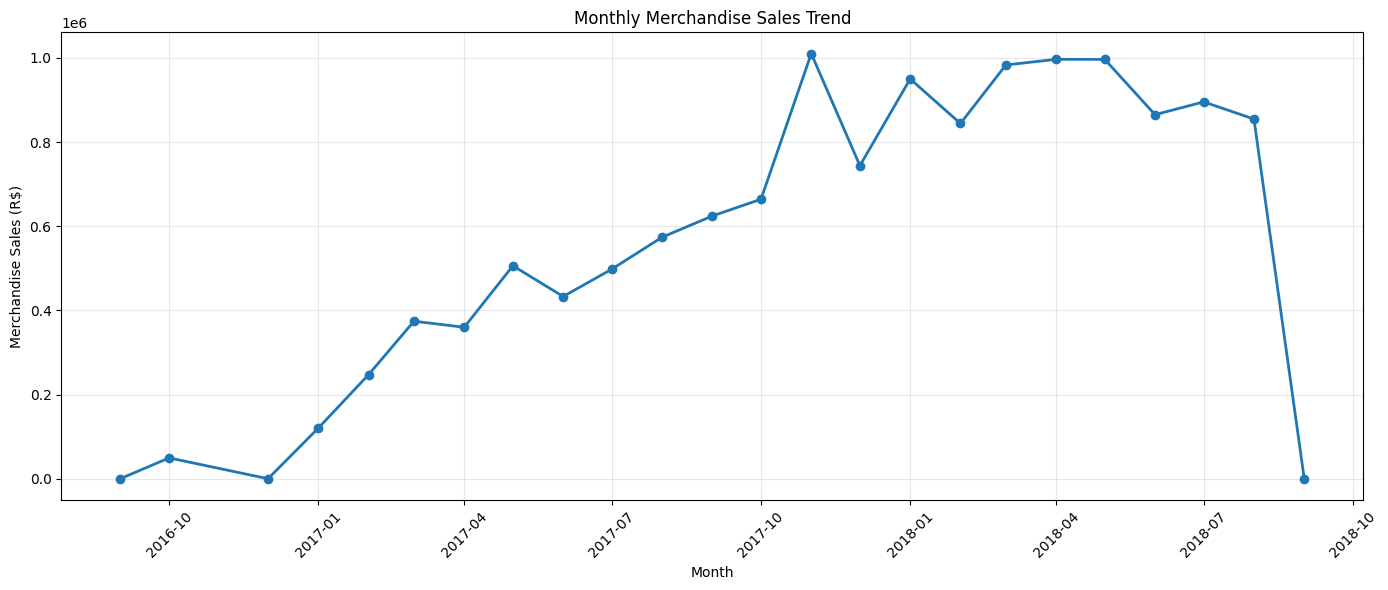

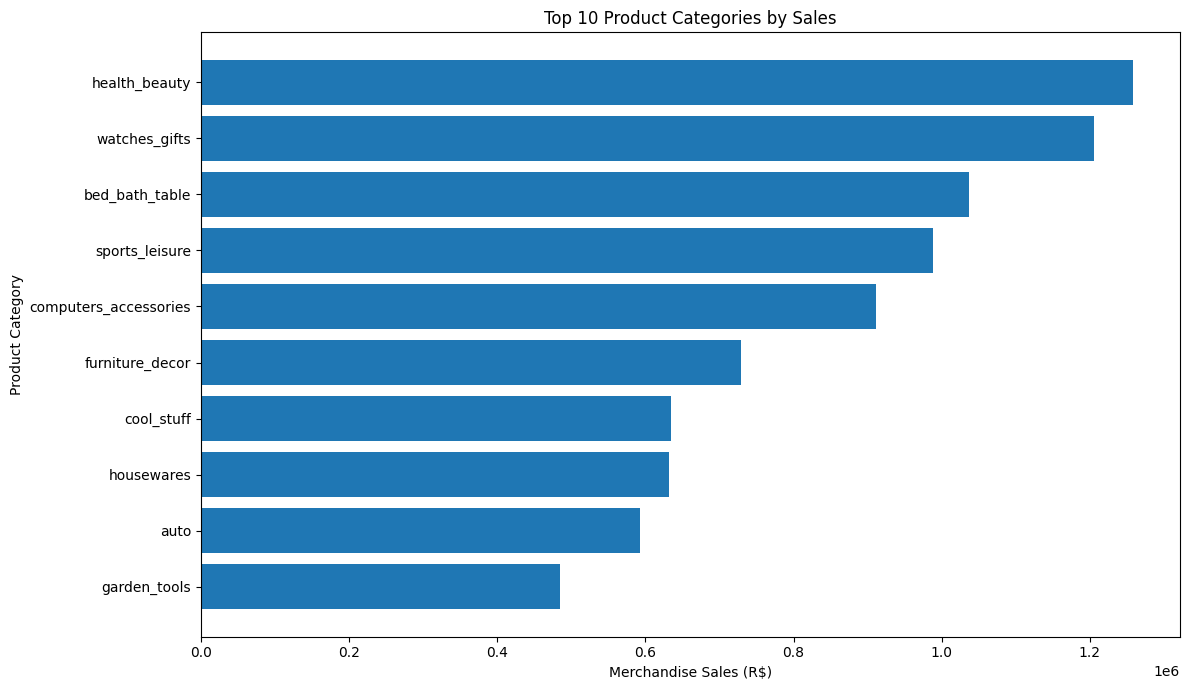

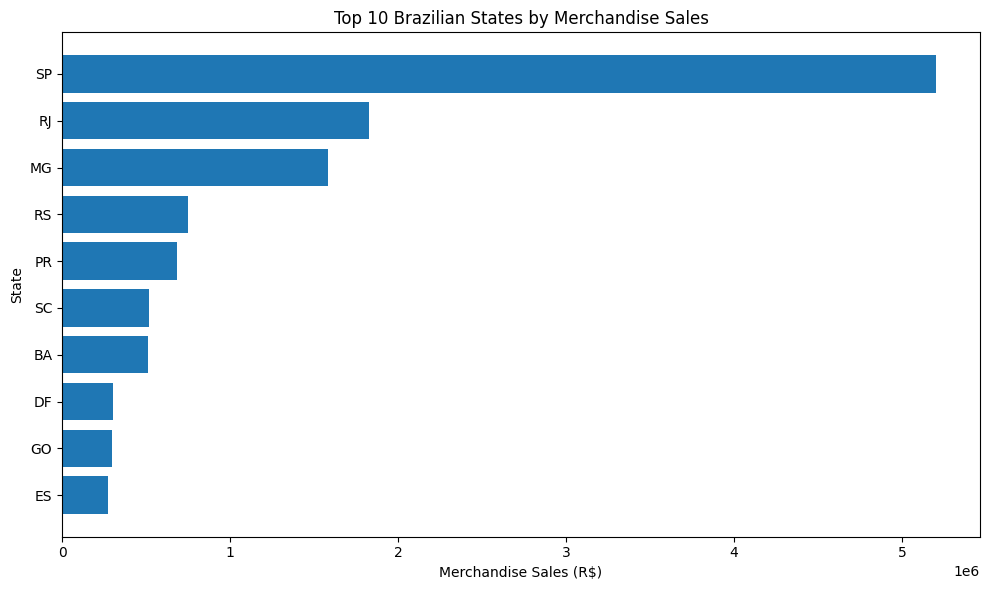

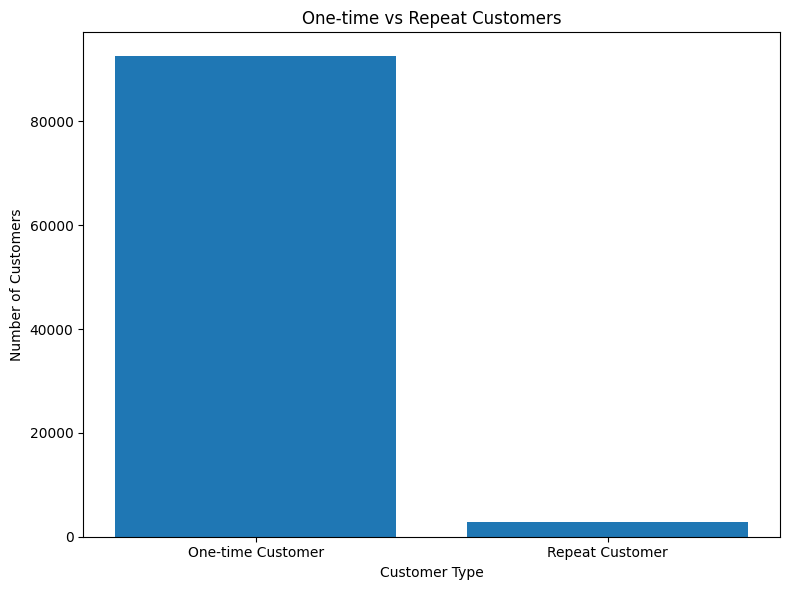

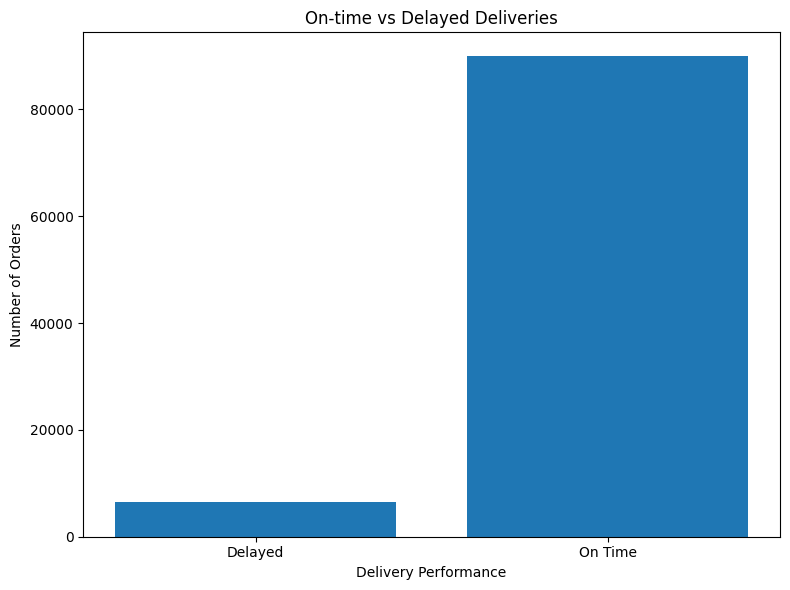

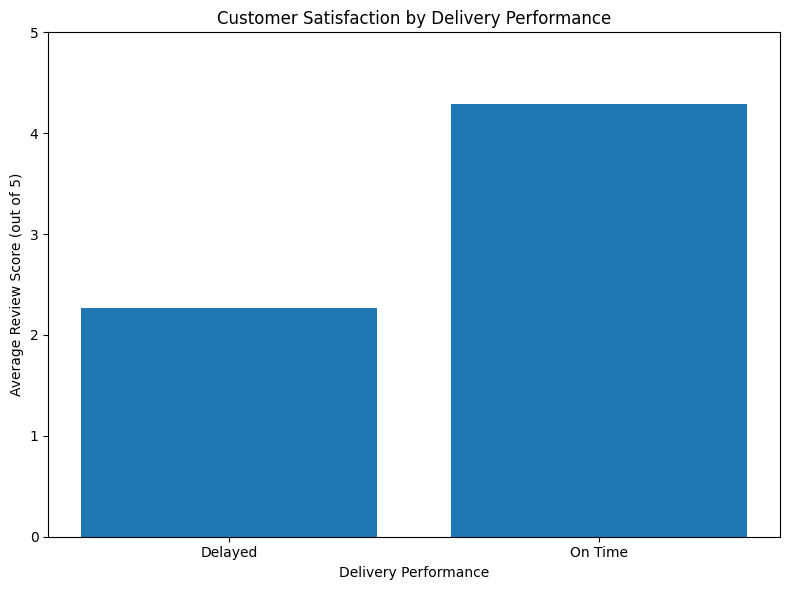

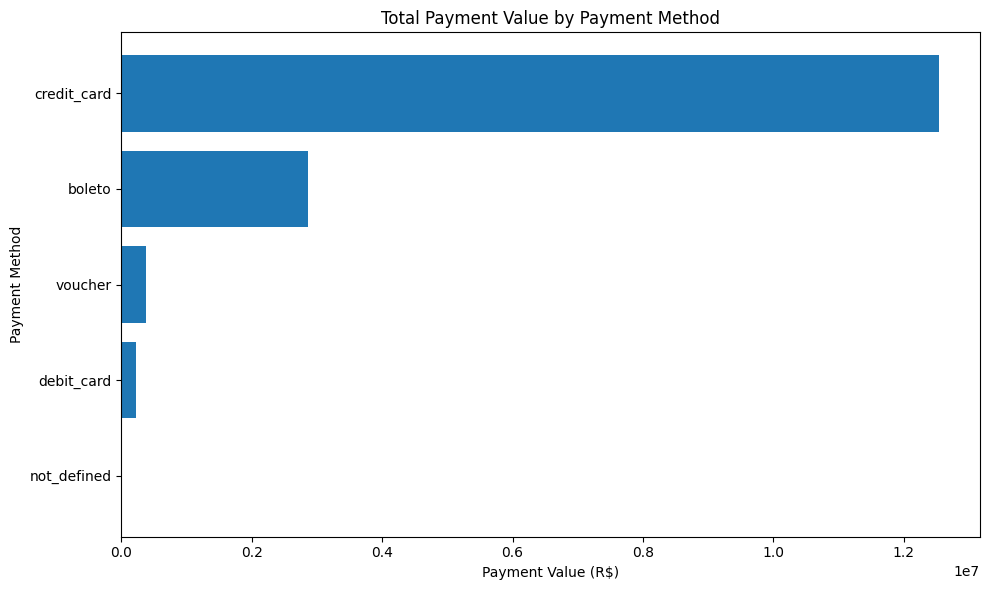

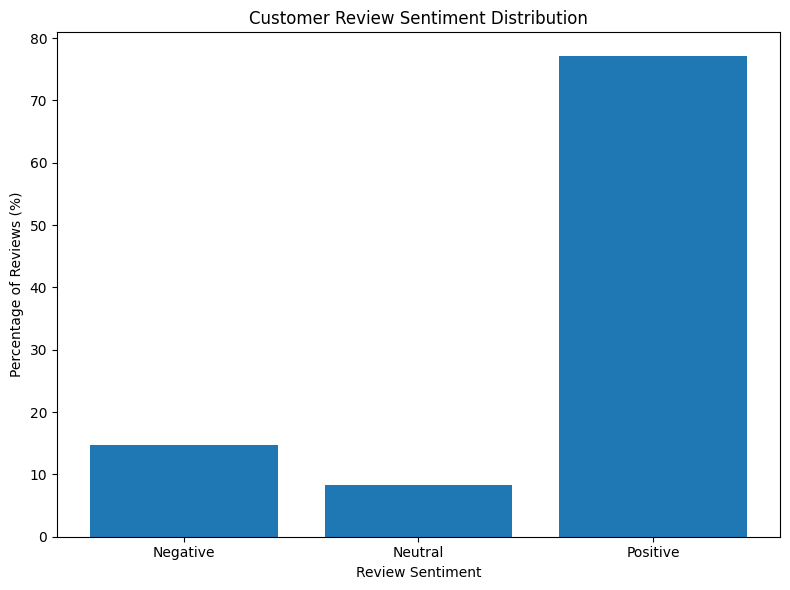

VISUALISATION COMPLETE
Number of charts: 8
ZIP file: /content/olist_visualizations.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:

import matplotlib.pyplot as plt
import pandas as pd
import os
import zipfile

# Create folder for visualisations
chart_folder = "/content/olist_visualizations"
os.makedirs(chart_folder, exist_ok=True)

# Reusable chart-saving function
def save_chart(filename):
    plt.tight_layout()
    plt.savefig(
        os.path.join(chart_folder, filename),
        dpi=300,
        bbox_inches="tight"
    )
    plt.show()
    plt.close()


# 1. MONTHLY SALES TREND
monthly_chart = monthly_sales.copy()
monthly_chart["purchase_month"] = pd.to_datetime(
    monthly_chart["purchase_month"].astype(str)
)

# Remove only the incomplete first and last months
monthly_chart = monthly_chart[
    monthly_chart["purchase_month"].astype(str).isin(
        ["2016-09", "2018-09"]
    ) == False
]

plt.figure(figsize=(14, 6))
plt.plot(
    monthly_chart["purchase_month"],
    monthly_chart["merchandise_sales"],
    marker="o",
    linewidth=2
)
plt.title("Monthly Merchandise Sales Trend")
plt.xlabel("Month")
plt.ylabel("Merchandise Sales (R$)")
plt.xticks(rotation=45)
plt.grid(alpha=0.3)
save_chart("01_monthly_sales.png")


# 2. TOP 10 PRODUCT CATEGORIES
top_categories = category_performance.nlargest(
    10, "merchandise_sales"
).sort_values("merchandise_sales")

plt.figure(figsize=(12, 7))
plt.barh(
    top_categories["product_category_name_english"],
    top_categories["merchandise_sales"]
)
plt.title("Top 10 Product Categories by Sales")
plt.xlabel("Merchandise Sales (R$)")
plt.ylabel("Product Category")
save_chart("02_top_product_categories.png")


# 3. TOP 10 STATES BY SALES
top_states = state_sales.nlargest(
    10, "merchandise_sales"
).sort_values("merchandise_sales")

plt.figure(figsize=(10, 6))
plt.barh(
    top_states["customer_state"],
    top_states["merchandise_sales"]
)
plt.title("Top 10 Brazilian States by Merchandise Sales")
plt.xlabel("Merchandise Sales (R$)")
plt.ylabel("State")
save_chart("03_state_sales.png")


# 4. CUSTOMER PURCHASING BEHAVIOUR
plt.figure(figsize=(8, 6))
plt.bar(
    customer_summary["customer_type"],
    customer_summary["customers"]
)
plt.title("One-time vs Repeat Customers")
plt.xlabel("Customer Type")
plt.ylabel("Number of Customers")
save_chart("04_customer_behaviour.png")


# 5. DELIVERY PERFORMANCE
plt.figure(figsize=(8, 6))
plt.bar(
    delivery_performance["delivery_performance"],
    delivery_performance["total_orders"]
)
plt.title("On-time vs Delayed Deliveries")
plt.xlabel("Delivery Performance")
plt.ylabel("Number of Orders")
save_chart("05_delivery_performance.png")


# 6. DELIVERY PERFORMANCE AND CUSTOMER SATISFACTION
plt.figure(figsize=(8, 6))
plt.bar(
    corrected_satisfaction["delivery_performance"],
    corrected_satisfaction["average_review_score"]
)
plt.title("Customer Satisfaction by Delivery Performance")
plt.xlabel("Delivery Performance")
plt.ylabel("Average Review Score (out of 5)")
plt.ylim(0, 5)
save_chart("06_delivery_and_satisfaction.png")


# 7. PAYMENT METHOD PERFORMANCE
payment_chart = payment_performance.sort_values(
    "total_payment_value"
)

plt.figure(figsize=(10, 6))
plt.barh(
    payment_chart["payment_type"],
    payment_chart["total_payment_value"]
)
plt.title("Total Payment Value by Payment Method")
plt.xlabel("Payment Value (R$)")
plt.ylabel("Payment Method")
save_chart("07_payment_methods.png")


# 8. CUSTOMER REVIEW SENTIMENT
plt.figure(figsize=(8, 6))
plt.bar(
    review_sentiment["review_category"],
    review_sentiment["percentage"]
)
plt.title("Customer Review Sentiment Distribution")
plt.xlabel("Review Sentiment")
plt.ylabel("Percentage of Reviews (%)")
save_chart("08_review_sentiment.png")


# PACKAGE ALL CHARTS INTO A ZIP FILE
zip_path = "/content/olist_visualizations.zip"

with zipfile.ZipFile(zip_path, "w") as zip_file:
    for filename in os.listdir(chart_folder):
        full_path = os.path.join(chart_folder, filename)
        zip_file.write(full_path, arcname=filename)

print("VISUALISATION COMPLETE")
print("Number of charts:", len(os.listdir(chart_folder)))
print("ZIP file:", zip_path)

from google.colab import files
files.download(zip_path)


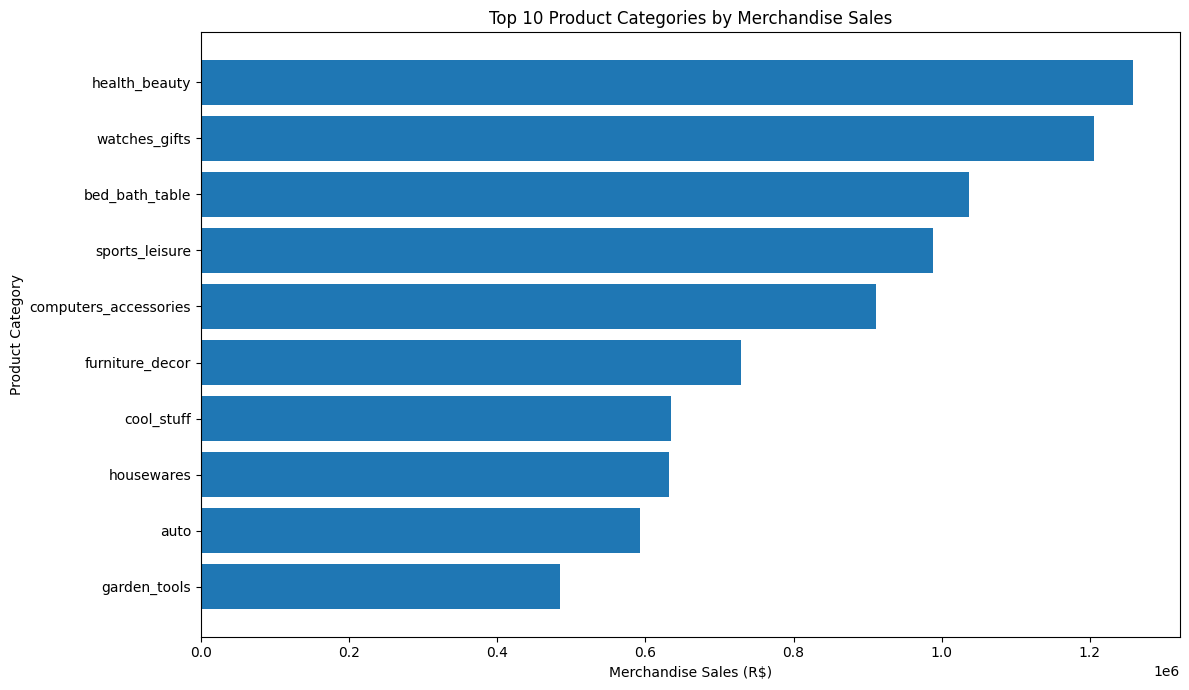

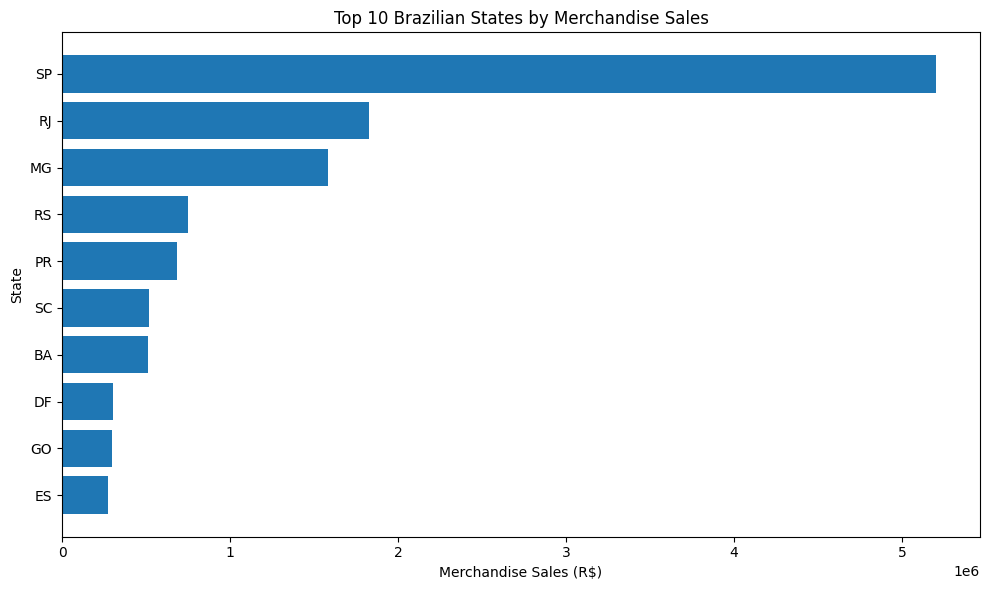

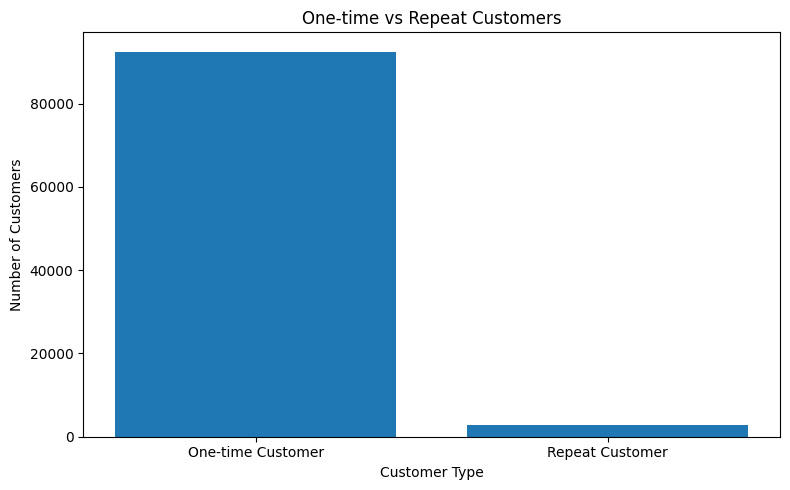

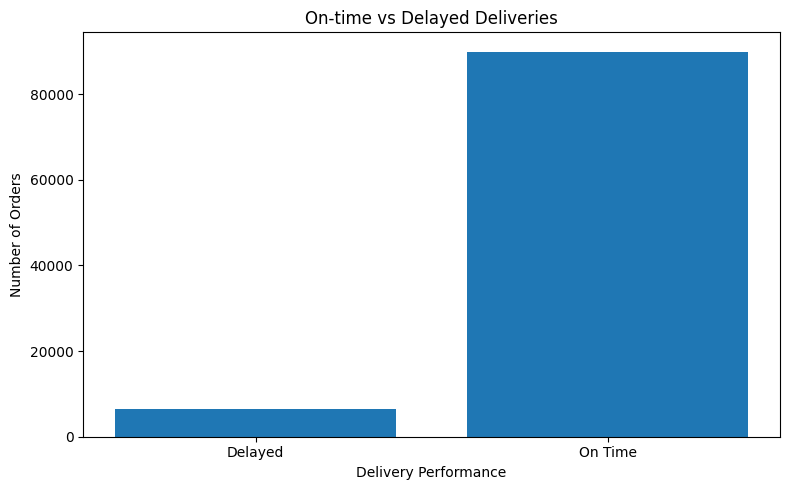

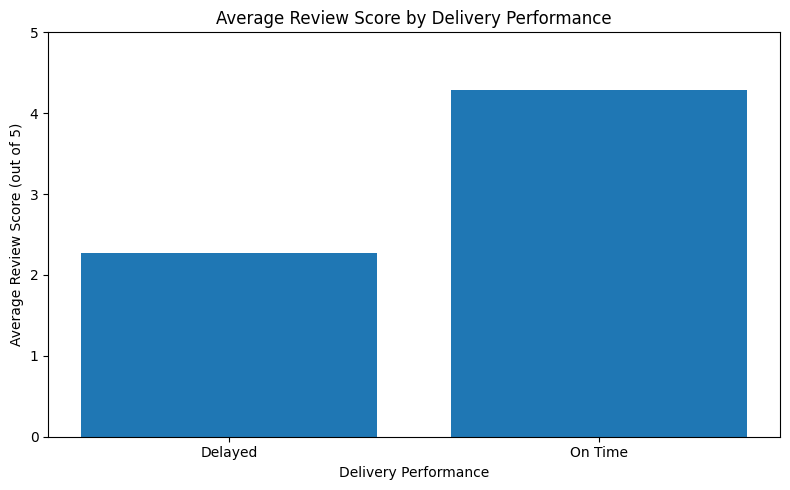

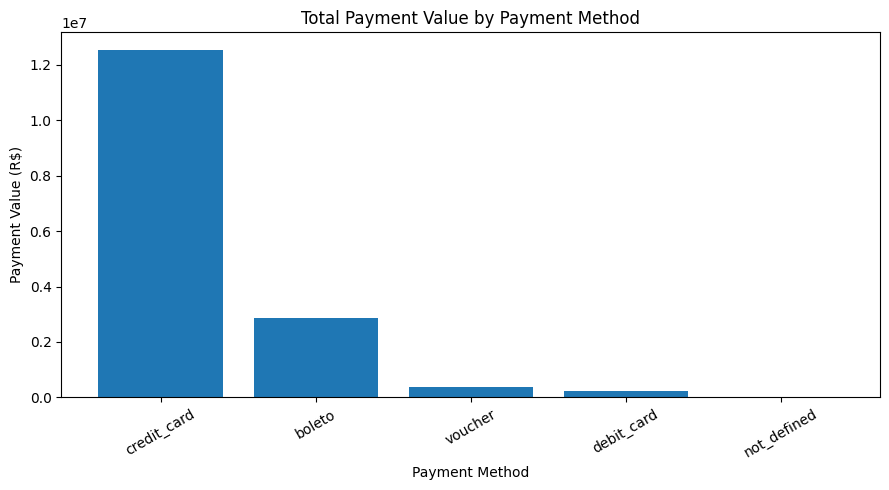

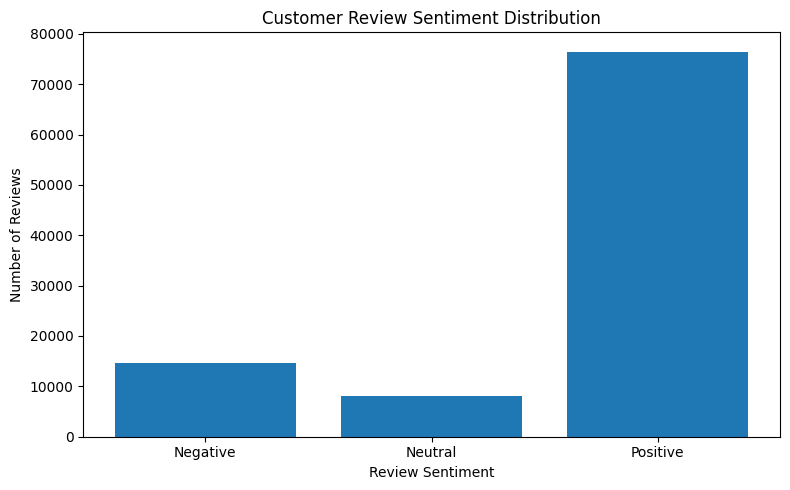

VISUALISATION COMPLETE
Charts created: 15
ZIP file: /content/olist_visualizations.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:

import matplotlib.pyplot as plt
import pandas as pd
import os
import zipfile

# Create folder for charts
chart_folder = "/content/olist_visualizations"
os.makedirs(chart_folder, exist_ok=True)

def save_chart(filename):
    plt.tight_layout()
    plt.savefig(
        os.path.join(chart_folder, filename),
        dpi=300,
        bbox_inches="tight"
    )
    plt.show()
    plt.close()

# 1. Top 10 product categories by sales
top_categories = category_performance.nlargest(
    10, "merchandise_sales"
).sort_values("merchandise_sales")

plt.figure(figsize=(12, 7))
plt.barh(
    top_categories["product_category_name_english"],
    top_categories["merchandise_sales"]
)
plt.title("Top 10 Product Categories by Merchandise Sales")
plt.xlabel("Merchandise Sales (R$)")
plt.ylabel("Product Category")
save_chart("01_top_product_categories.png")

# 2. Top 10 states by sales
top_states = state_sales.nlargest(
    10, "merchandise_sales"
).sort_values("merchandise_sales")

plt.figure(figsize=(10, 6))
plt.barh(
    top_states["customer_state"],
    top_states["merchandise_sales"]
)
plt.title("Top 10 Brazilian States by Merchandise Sales")
plt.xlabel("Merchandise Sales (R$)")
plt.ylabel("State")
save_chart("02_top_states.png")

# 3. Customer purchasing behaviour
plt.figure(figsize=(8, 5))
plt.bar(
    customer_summary["customer_type"],
    customer_summary["customers"]
)
plt.title("One-time vs Repeat Customers")
plt.xlabel("Customer Type")
plt.ylabel("Number of Customers")
save_chart("03_customer_behaviour.png")

# 4. Delivery performance
plt.figure(figsize=(8, 5))
plt.bar(
    delivery_performance["delivery_performance"],
    delivery_performance["total_orders"]
)
plt.title("On-time vs Delayed Deliveries")
plt.xlabel("Delivery Performance")
plt.ylabel("Number of Orders")
save_chart("04_delivery_performance.png")

# 5. Customer satisfaction by delivery performance
plt.figure(figsize=(8, 5))
plt.bar(
    corrected_satisfaction["delivery_performance"],
    corrected_satisfaction["average_review_score"]
)
plt.title("Average Review Score by Delivery Performance")
plt.xlabel("Delivery Performance")
plt.ylabel("Average Review Score (out of 5)")
plt.ylim(0, 5)
save_chart("05_delivery_customer_satisfaction.png")

# 6. Payment methods by total payment value
plt.figure(figsize=(9, 5))
plt.bar(
    payment_performance["payment_type"],
    payment_performance["total_payment_value"]
)
plt.title("Total Payment Value by Payment Method")
plt.xlabel("Payment Method")
plt.ylabel("Payment Value (R$)")
plt.xticks(rotation=30)
save_chart("06_payment_methods.png")

# 7. Customer review sentiment
plt.figure(figsize=(8, 5))
plt.bar(
    review_sentiment["review_category"],
    review_sentiment["review_records"]
)
plt.title("Customer Review Sentiment Distribution")
plt.xlabel("Review Sentiment")
plt.ylabel("Number of Reviews")
save_chart("07_review_sentiment.png")

# Package charts into ZIP
zip_path = "/content/olist_visualizations.zip"

with zipfile.ZipFile(zip_path, "w") as zip_file:
    for filename in os.listdir(chart_folder):
        full_path = os.path.join(chart_folder, filename)
        zip_file.write(full_path, arcname=filename)

print("VISUALISATION COMPLETE")
print("Charts created:", len(os.listdir(chart_folder)))
print("ZIP file:", zip_path)

from google.colab import files
files.download(zip_path)
